# Team V2G — Solar curtailment in India (2022–2025) and V2G feasibility

Run each cell in order from the `V2G_Feasibility_2026` folder. Every cell saves its tables to `results/` and charts to `figures/`.

**Cell 1:** load all Grid-India (Mendeley) files and IEX DAM data into clean hourly tables, and report coverage.

In [2]:
# =====================================================================================
# CELL 1 - Load all Grid-India (Mendeley) files + IEX DAM into clean hourly tables
#   Handles both Mendeley formats:
#     (a) raw SCADA export  : sheets _osi_config + Sheet1, tags like ALL_IND_SOLAR|P,
#                             10-s (2023) or 5-min (2022) samples -> averaged to hourly
#     (b) clean hourly table: Timestamp, Demand (MW), Wind (MW), Solar (MW), Total Generation (MW)
#   Outputs (results/):
#     01_grid_hourly.csv      one row per hour: demand, solar, wind, thermal, hydro, gas, nuclear, total_gen
#     01_coverage_by_month.csv  what each month contains, gaps, peaks, energy
#     01_files_read.csv       which file gave which format / months
#     01_iex_hourly.csv       IEX DAM hourly: MCP, purchase bid, sell bid, cleared volume
#   Run from the V2G_Feasibility_2026 folder. Re-runs are fast (per-file cache in data/cache/).
# =====================================================================================
import os, glob, warnings, datetime as dt
import numpy as np, pandas as pd
from openpyxl import load_workbook
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

BASE  = os.path.abspath(".")
RAW   = os.path.join(BASE, "data", "mendeley_raw")
IEX   = os.path.join(BASE, "data", "iex", "csv_data")
RES   = os.path.join(BASE, "results")
CACHE = os.path.join(BASE, "data", "cache")
os.makedirs(RES, exist_ok=True); os.makedirs(CACHE, exist_ok=True)

SCADA_TAGS = {"TOTAL_THM_ONLY|P": "thermal", "TOTAL_NLDC_HYD|P": "hydro", "TOTAL_NLDC_GAS|P": "gas",
              "TOTAL_NLDC_NPC|P": "nuclear", "ALL_INDIA_WIND|P": "wind", "ALL_IND_SOLAR|P": "solar",
              "NLDC_DEMAND|P": "demand"}
HOURLY_COLS = {"timestamp": "time", "demand (mw)": "demand", "wind (mw)": "wind", "solar (mw)": "solar",
               "total generation (mw)": "total_gen"}
COLS = ["demand", "solar", "wind", "thermal", "hydro", "gas", "nuclear", "total_gen"]

def to_float(v):
    try:
        x = float(v); return x if np.isfinite(x) else np.nan
    except (TypeError, ValueError):
        return np.nan

def to_time(v):
    if isinstance(v, dt.datetime): return v
    if v is None or str(v).strip() == "": return None
    try: return pd.to_datetime(str(v), dayfirst=True).to_pydatetime()
    except Exception: return None

def detect(wb):
    """Find the data sheet and header row; returns (format, sheet, header_row, {col: name})."""
    for ws in wb.worksheets:
        for r, row in enumerate(ws.iter_rows(min_row=1, max_row=6, values_only=True), start=1):
            cells = [str(c).strip() if c is not None else "" for c in row]
            if any(c in SCADA_TAGS for c in cells):
                return "scada", ws.title, r, {i: SCADA_TAGS[c] for i, c in enumerate(cells) if c in SCADA_TAGS}
            low = [c.lower() for c in cells]
            if "solar (mw)" in low and "timestamp" in low:
                return "hourly", ws.title, r, {i: HOURLY_COLS[c] for i, c in enumerate(low) if c in HOURLY_COLS}
    return None, None, None, None

def read_file(path):
    cache = os.path.join(CACHE, os.path.basename(path) + ".csv")
    if os.path.exists(cache) and os.path.getmtime(cache) > os.path.getmtime(path):
        d = pd.read_csv(cache, parse_dates=["time"]); return d, d["format"].iloc[0]
    wb = load_workbook(path, read_only=True, data_only=True)
    fmt, sheet, hdr, cmap = detect(wb)
    if fmt is None:
        wb.close(); return None, "unrecognised"
    ws = wb[sheet]; rows = ws.iter_rows(min_row=hdr + 1, values_only=True)
    if fmt == "scada":                               # stream rows, average into hours
        sums, cnt = {}, {}
        for row in rows:
            t = to_time(row[0])
            if t is None: continue
            h = t.replace(minute=0, second=0, microsecond=0)
            s = sums.setdefault(h, {k: 0.0 for k in cmap.values()}); c = cnt.setdefault(h, {k: 0 for k in cmap.values()})
            for i, k in cmap.items():
                x = to_float(row[i]) if i < len(row) else np.nan
                if not np.isnan(x): s[k] += x; c[k] += 1
        recs = [{"time": h, **{k: (sums[h][k] / cnt[h][k] if cnt[h][k] else np.nan) for k in cmap.values()},
                 "n_samples": max(cnt[h].values())} for h in sorted(sums)]
        d = pd.DataFrame(recs)
    else:                                             # already hourly
        recs = []
        for row in rows:
            rec = {k: row[i] if i < len(row) else None for i, k in cmap.items()}
            t = to_time(rec.pop("time", None))
            if t is None: continue
            recs.append({"time": t, **{k: to_float(v) for k, v in rec.items()}, "n_samples": 1})
        d = pd.DataFrame(recs)
        d["time"] = d["time"].dt.floor("h"); d = d.groupby("time", as_index=False).mean()
    wb.close()
    for c in COLS:
        if c not in d: d[c] = np.nan
    d["format"] = fmt; d["file"] = os.path.basename(path)
    d.to_csv(cache, index=False)
    return d, fmt

# ---------------------------------------------------------------- Grid-India / Mendeley
files = sorted(glob.glob(os.path.join(RAW, "**", "*.xlsx"), recursive=True))                  # includes subfolders
files = [f for f in files if not os.path.basename(f).startswith("~$")]          # skip Excel lock files
print(f"Found {len(files)} Mendeley files in {RAW}")
frames, log = [], []
for f in tqdm(files, desc="Reading Mendeley files"):
    try:
        d, fmt = read_file(f)
    except Exception as e:
        d, fmt = None, f"error: {e}"
    if d is None or d.empty:
        log.append(dict(file=os.path.basename(f), format=fmt, first=None, last=None, hours=0)); continue
    frames.append(d)
    log.append(dict(file=os.path.basename(f), format=fmt, first=d.time.min(), last=d.time.max(), hours=len(d),
                    samples_per_hour=round(d.n_samples.median())))
log = pd.DataFrame(log); log.to_csv(os.path.join(RES, "01_files_read.csv"), index=False)

grid = pd.concat(frames, ignore_index=True)
grid["prio"] = grid["format"].map({"scada": 0, "hourly": 1})                    # scada has the full generation mix
n_before = len(grid)
grid = grid.sort_values(["time", "prio"]).drop_duplicates("time", keep="first").drop(columns="prio")
grid["total_gen"] = grid["total_gen"].fillna(grid[["thermal", "hydro", "gas", "nuclear", "wind", "solar"]]
                                             .clip(lower=0).sum(axis=1, min_count=6))
grid = grid[["time"] + COLS + ["n_samples", "format", "file"]].reset_index(drop=True)
grid.to_csv(os.path.join(RES, "01_grid_hourly.csv"), index=False)

# coverage report by month
grid["month"] = grid.time.dt.to_period("M")
cov = grid.groupby("month").agg(hours=("time", "size"), format=("format", lambda s: "/".join(sorted(set(s)))),
                                demand_peak_GW=("demand", lambda s: s.max() / 1e3),
                                solar_peak_GW=("solar", lambda s: s.max() / 1e3),
                                solar_TWh=("solar", lambda s: s.clip(lower=0).sum() / 1e6),
                                demand_TWh=("demand", lambda s: s.sum() / 1e6),
                                has_mix=("thermal", lambda s: s.notna().mean() > 0.9),
                                missing_solar_h=("solar", lambda s: s.isna().sum()))
cov["expected_hours"] = [p.days_in_month * 24 for p in cov.index]
cov["missing_hours"] = cov.expected_hours - cov.hours
cov = cov.round(2); cov.to_csv(os.path.join(RES, "01_coverage_by_month.csv"))

# ---------------------------------------------------------------- IEX day-ahead market
iex = []
for f in tqdm(sorted(glob.glob(os.path.join(IEX, "*.csv"))), desc="Reading IEX files"):
    d = pd.read_csv(f)
    d.columns = [c.strip() for c in d.columns]
    mcp = [c for c in d.columns if c.startswith("MCP")][0]
    d["Date"] = pd.to_datetime(d["Date"], format="%d-%m-%Y", errors="coerce")      # repeated header rows -> NaT
    d["Hour"] = pd.to_numeric(d["Hour"], errors="coerce")
    d = d.dropna(subset=["Date", "Hour"])
    d["time"] = d["Date"] + pd.to_timedelta(d["Hour"].astype(int) - 1, unit="h")
    for c in ["Purchase Bid (MW)", "Sell Bid (MW)", "MCV (MW)", mcp]:
        d[c] = pd.to_numeric(d[c].astype(str).str.replace(",", ""), errors="coerce")
    iex.append(d.groupby("time").agg(mcp_rs_mwh=(mcp, "mean"), purchase_bid_mw=("Purchase Bid (MW)", "mean"),
                                     sell_bid_mw=("Sell Bid (MW)", "mean"), cleared_mw=("MCV (MW)", "mean")))
iex = pd.concat(iex).sort_index(); iex["sell_buy_ratio"] = iex.sell_bid_mw / iex.purchase_bid_mw
iex.to_csv(os.path.join(RES, "01_iex_hourly.csv"))

# ---------------------------------------------------------------- summary
pd.set_option("display.width", 200)
print("\nFiles read:\n", log.to_string(index=False))
print(f"\nGrid-India hourly: {len(grid):,} hours, {grid.time.min()} -> {grid.time.max()} "
      f"({n_before - len(grid):,} duplicate hours dropped, scada preferred)")
print("\nCoverage by month:\n", cov.to_string())
print(f"\nIEX hourly: {len(iex):,} hours, {iex.index.min()} -> {iex.index.max()}")
print(iex.groupby(iex.index.year).agg(mean_MCP=("mcp_rs_mwh", "mean"), mean_sell_buy=("sell_buy_ratio", "mean")).round(2))


Found 29 Mendeley files in data/mendeley_raw


Reading IEX files: 100%|██████████| 3/3 [00:00<00:00,  8.59it/s]



Files read:
                         file format      first                last  hours  samples_per_hour
             April 2022.xlsx  scada 2022-04-01 2022-04-30 23:00:00    720                12
             April 2023.xlsx  scada 2023-04-01 2023-04-30 23:00:00    720               360
            August 2022.xlsx  scada 2022-08-01 2022-08-31 23:00:00    744                12
            August 2023.xlsx  scada 2023-08-01 2023-08-31 23:00:00    744               360
          December 2021.xlsx  scada 2021-12-01 2021-12-31 23:00:00    744                12
          December 2022.xlsx  scada 2022-12-01 2022-12-31 23:00:00    744               360
          December 2023.xlsx  scada 2023-12-01 2023-12-31 23:00:00    744               360
          February 2022.xlsx  scada 2022-02-01 2022-02-28 23:00:00    672                12
          February 2023.xlsx  scada 2023-02-01 2023-02-28 23:00:00    672               360
           January 2022.xlsx  scada 2022-01-01 2022-01-31 23:00:00

**Cell 2:** clean the hourly data (feed dropouts, frozen solar, sensor spikes), then build solar and demand curves for every year.

Yearly curves: 100%|██████████| 5/5 [00:00<00:00, 181.76it/s]


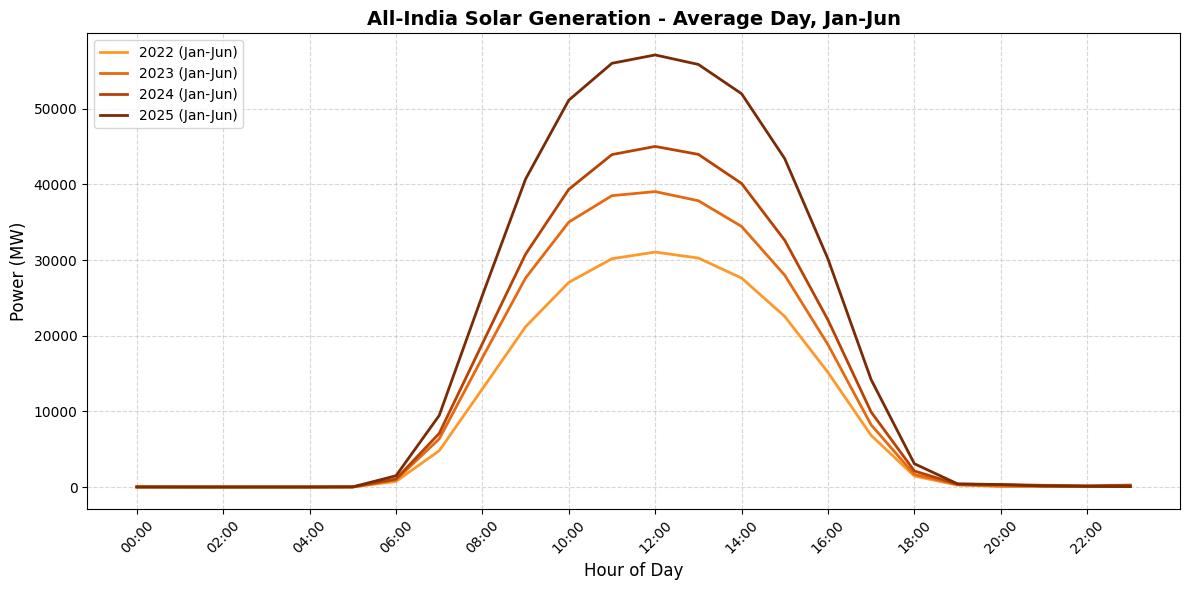

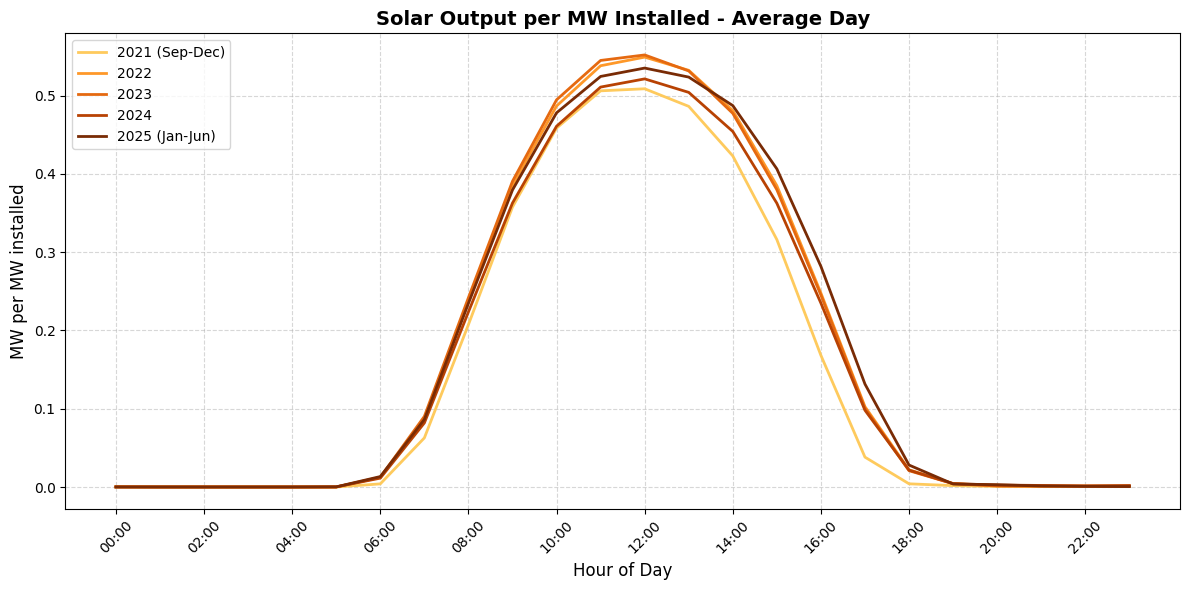

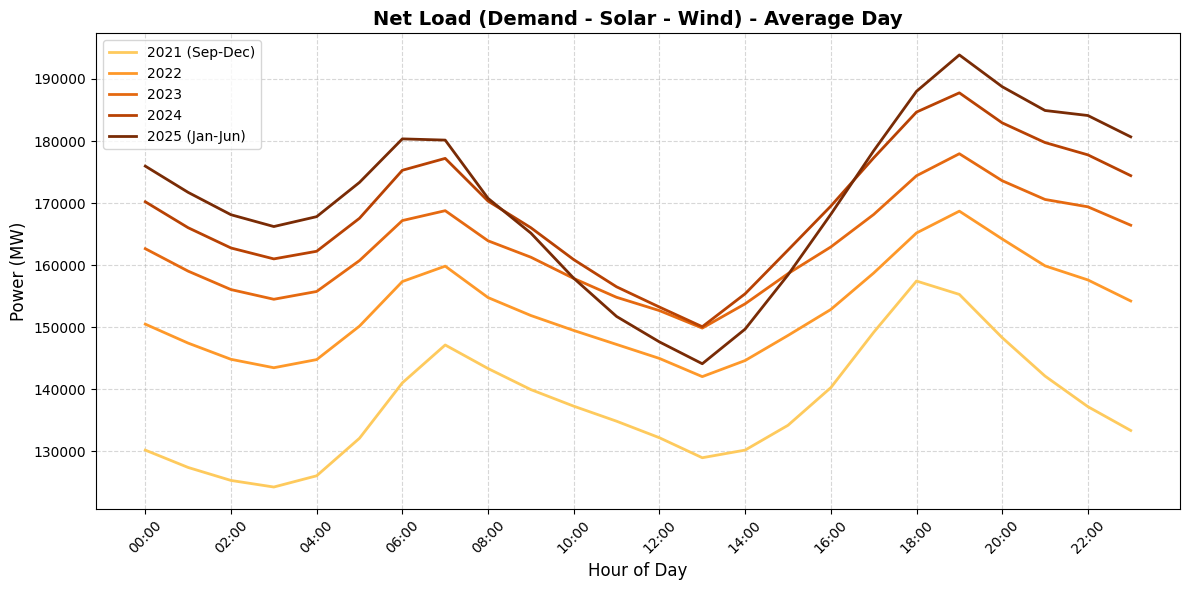

Load vs solar charts:   0%|          | 0/5 [00:00<?, ?it/s]

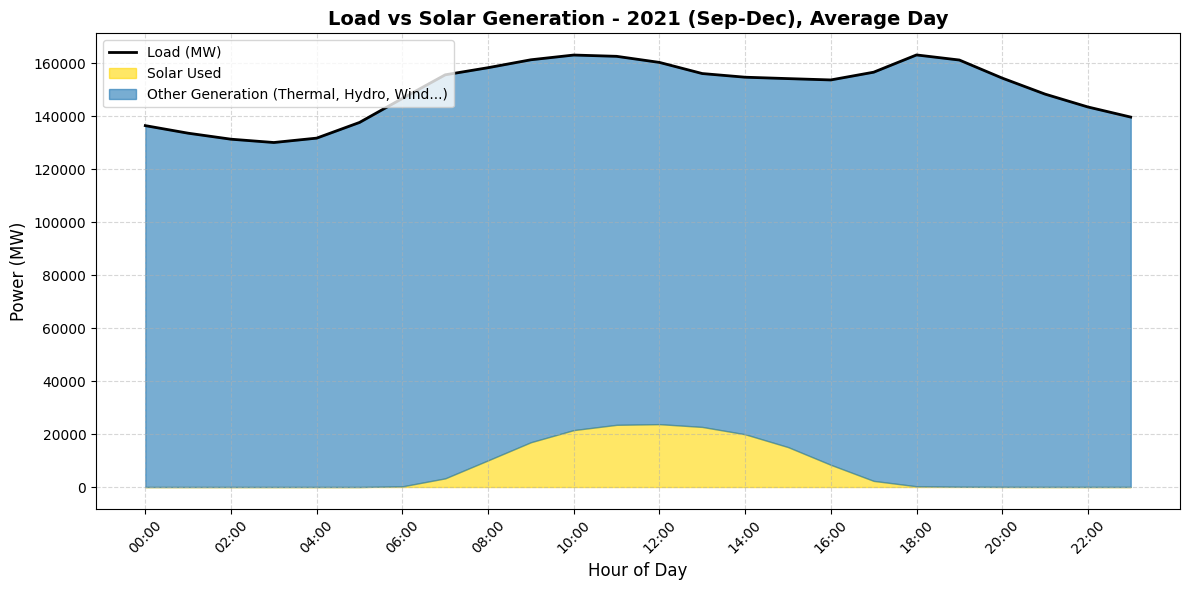

Load vs solar charts:  20%|██        | 1/5 [00:00<00:00,  4.87it/s]

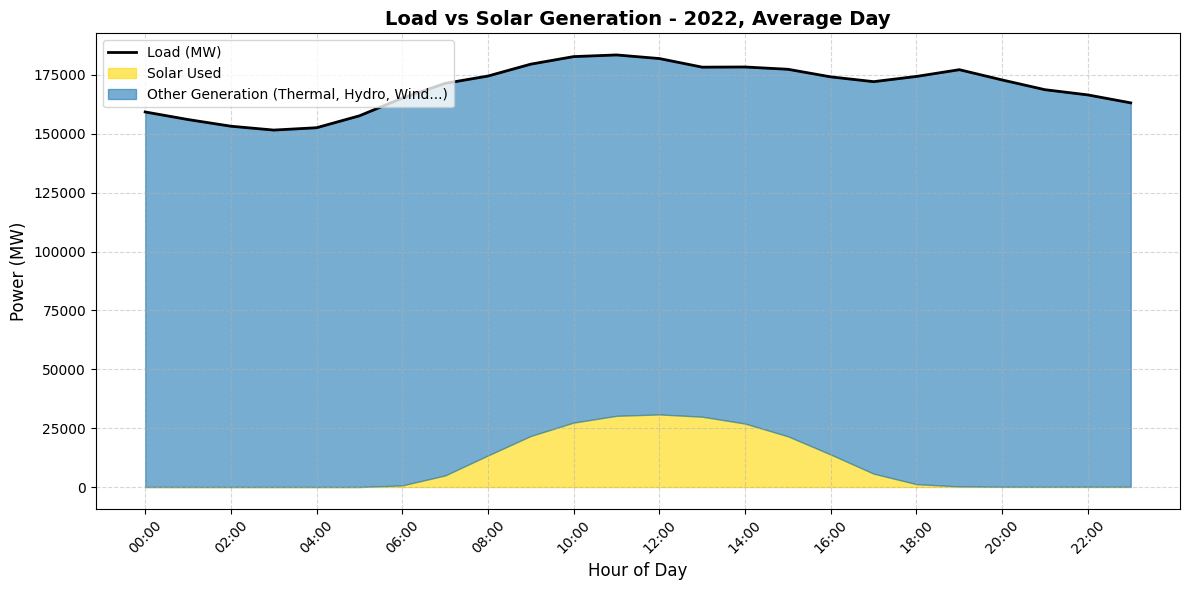

Load vs solar charts:  40%|████      | 2/5 [00:00<00:00,  5.02it/s]

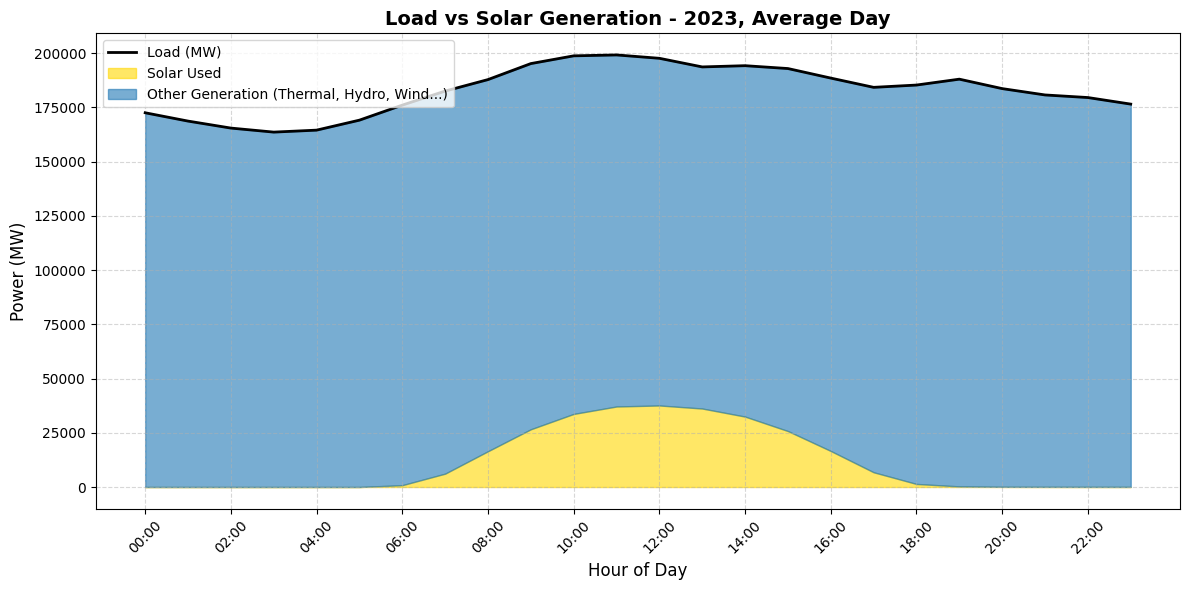

Load vs solar charts:  60%|██████    | 3/5 [00:00<00:00,  4.98it/s]

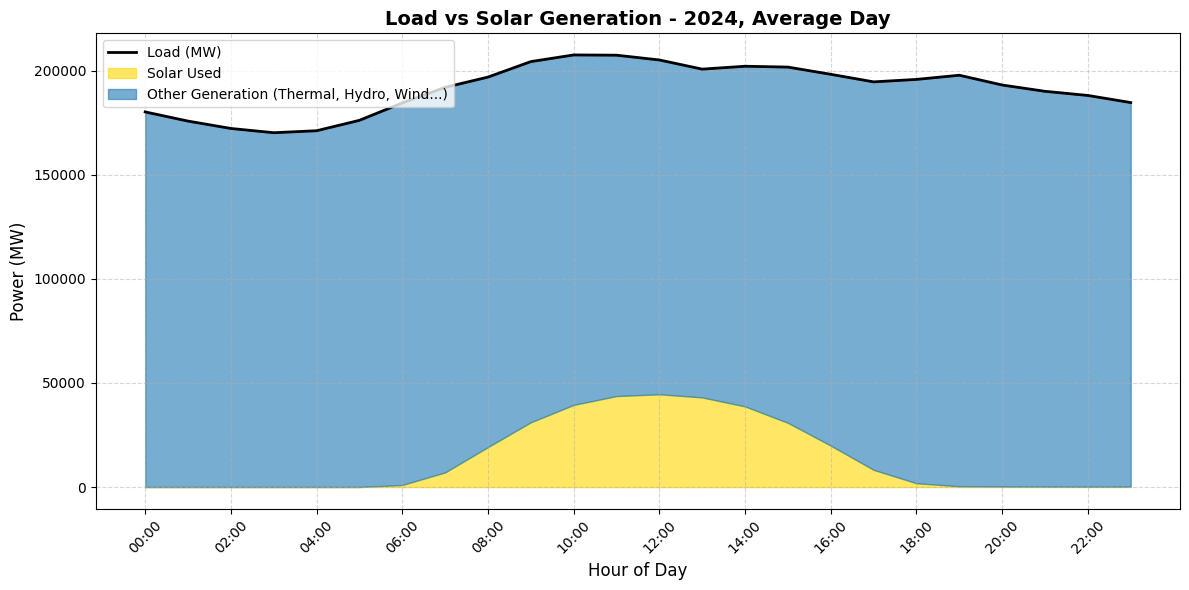

Load vs solar charts:  80%|████████  | 4/5 [00:00<00:00,  5.09it/s]

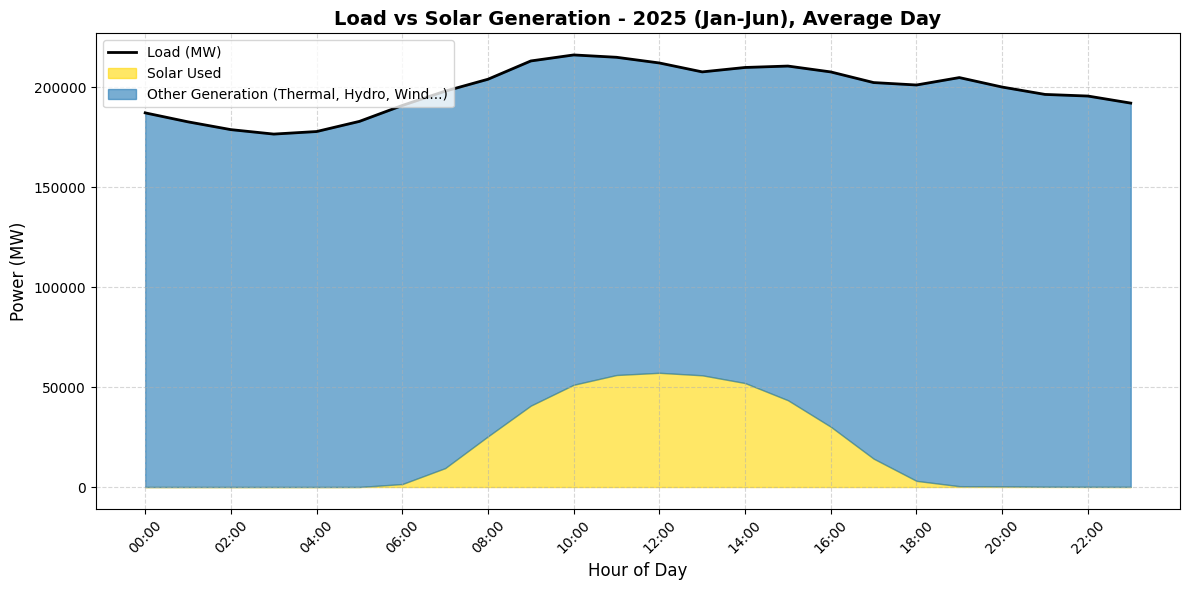

Load vs solar charts: 100%|██████████| 5/5 [00:01<00:00,  4.87it/s]

                                                            check                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              value
all: hours where generation and demand disagree by > 8% (dropped)                                                                                                                                                                                                                                                                                                                                                                                                  

In [3]:
# =====================================================================================
# CELL 2 - Clean the hourly data, then build solar + demand curves for every year
#   Cleaning (logged in results/02_cleaning_log.csv):
#     all     : hours where total generation and demand disagree by > 8% -> feed dropout, dropped
#     demand  : zero / < 60% of 7-day median -> outage; gaps <= 6 h interpolated, longer gaps dropped
#     nuclear : > 2x monthly median -> sensor spike, forward-filled
#     solar   : night-time offset removed; days where solar is "frozen" (stuck value, or > 10% of the
#               month's peak at 1-4 am) are flagged and excluded from the curves
#   Solar per MW installed = clean solar / installed capacity that month (MNRE / Mercom anchors)
#   Outputs: results/02_*.csv and figures/02_*.png
# =====================================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm

BASE = os.path.abspath("."); RES = os.path.join(BASE, "results"); FIG = os.path.join(BASE, "figures")
os.makedirs(FIG, exist_ok=True)
g = pd.read_csv(os.path.join(RES, "01_grid_hourly.csv"), parse_dates=["time"]).set_index("time").sort_index()
g = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq="h"))          # make missing hours explicit
log = []

# ---------------------------------------------------------------- 1. cleaning
mismatch = (g["total_gen"] - g["demand"]).abs() / g["demand"] > 0.08           # partial-hour feed dropouts
log.append(("all: hours where generation and demand disagree by > 8% (dropped)", int(mismatch.sum())))
g.loc[mismatch, ["demand", "solar", "wind"]] = np.nan
med7 = g["demand"].rolling(24 * 7, center=True, min_periods=24).median()
bad_d = (g["demand"] <= 0) | (g["demand"] < 0.6 * med7) | g["demand"].isna()
log.append(("demand: outage / missing hours", int(bad_d.sum())))
g.loc[bad_d, "demand"] = np.nan
g["demand"] = g["demand"].interpolate(limit=6, limit_area="inside")
log.append(("demand: hours still missing after 6-h interpolation", int(g["demand"].isna().sum())))

if g["nuclear"].notna().any():
    nmed = g["nuclear"].groupby(g.index.to_period("M")).transform("median")
    spike = g["nuclear"] > 2 * nmed
    log.append(("nuclear: sensor spikes", int(spike.sum())))
    g.loc[spike, "nuclear"] = np.nan; g["nuclear"] = g["nuclear"].ffill(limit=48)

hr = g.index.hour; day = g.index.normalize()
night = (hr <= 4) | (hr >= 21)
offset = g["solar"].where(night).groupby(day).transform("median").clip(lower=0).fillna(0)
log.append(("solar: mean night offset removed (MW)", round(float(offset.mean()), 1)))
g["solar_raw"] = g["solar"]; g["solar"] = (g["solar"] - offset).clip(lower=0)

month_peak = g["solar"].groupby(g.index.to_period("M")).transform(lambda s: s.quantile(0.99))
deep_night = (hr >= 1) & (hr <= 4)
frozen_night = (g["solar"].where(deep_night) > 0.10 * month_peak).groupby(day).transform("any")
stuck = g["solar"].gt(1000) & g["solar"].diff().abs().lt(1e-6)
stuck_run = stuck.groupby((~stuck).cumsum()).transform("sum") >= 3
bad_solar_day = (frozen_night | stuck_run.groupby(day).transform("any") | g["solar"].isna().groupby(day).transform("any"))
g["bad_solar_day"] = bad_solar_day
log.append(("solar: days flagged bad (frozen / stuck / missing)", int(bad_solar_day.groupby(day).first().sum())))
bad_days = sorted(set(day[bad_solar_day].date))
log.append(("solar: bad days list", ", ".join(str(d) for d in bad_days[:40]) + (" ..." if len(bad_days) > 40 else "")))

# ---------------------------------------------------------------- 2. installed solar capacity (MW, month-end)
anchors = pd.Series({"2021-09-30": 46.4e3, "2021-12-31": 49.0e3, "2022-12-31": 63.3e3,
                     "2023-12-31": 73.3e3, "2024-12-31": 98.0e3, "2025-06-30": 116.4e3})
anchors.index = pd.to_datetime(anchors.index)
cap_daily = anchors.reindex(pd.date_range(anchors.index.min(), anchors.index.max(), freq="D")).interpolate()
cap = cap_daily.reindex(day.unique()).reindex(day).values
g["solar_cap_mw"] = cap
g["solar_pu"] = g["solar"] / g["solar_cap_mw"]
cap_m = cap_daily.resample("ME").last().rename("installed_solar_MW"); cap_m.to_csv(os.path.join(RES, "02_solar_capacity_monthly.csv"))

g["net_load"] = g["demand"] - g["solar"] - g["wind"]
g.index.name = "time"; g.to_csv(os.path.join(RES, "02_grid_hourly_clean.csv"))
pd.DataFrame(log, columns=["check", "value"]).to_csv(os.path.join(RES, "02_cleaning_log.csv"), index=False)

# ---------------------------------------------------------------- 3. yearly curves + summary
good = g[~g["bad_solar_day"] & g["demand"].notna()].copy()
good["year"] = good.index.year; good["hour"] = good.index.hour; good["month"] = good.index.month
years = sorted(good["year"].unique())
label = {y: f"{y}" + (" (Sep-Dec)" if y == 2021 else " (Jan-Jun)" if y == 2025 else "") for y in years}
h1 = good[good["month"] <= 6]                                                   # like-for-like Jan-Jun

rows, prof = [], {}
for y in tqdm(years, desc="Yearly curves"):
    d = good[good.year == y]; d1 = h1[h1.year == y]
    prof[("solar_MW", y)] = d.groupby("hour")["solar"].mean()
    prof[("solar_per_MW", y)] = d.groupby("hour")["solar_pu"].mean()
    prof[("demand_MW", y)] = d.groupby("hour")["demand"].mean()
    prof[("net_load_MW", y)] = d.groupby("hour")["net_load"].mean()
    prof[("solar_MW_JanJun", y)] = d1.groupby("hour")["solar"].mean() if len(d1) else np.nan
    prof[("demand_MW_JanJun", y)] = d1.groupby("hour")["demand"].mean() if len(d1) else np.nan
    full = g[g.index.year == y]
    rows.append(dict(year=label[y], days_used=d.index.normalize().nunique(),
                     installed_solar_GW_end=round(full["solar_cap_mw"].iloc[-1] / 1e3, 1),
                     solar_TWh=round(full["solar"].sum() / 1e6, 1), demand_TWh=round(full["demand"].sum() / 1e6, 1),
                     solar_share_pct=round(full["solar"].sum() / full["demand"].sum() * 100, 1),
                     solar_peak_GW=round(d["solar"].max() / 1e3, 1), demand_peak_GW=round(d["demand"].max() / 1e3, 1),
                     noon_solar_GW_avg=round(d.loc[d.hour == 12, "solar"].mean() / 1e3, 1),
                     solar_per_MW_noon=round(d.loc[d.hour == 12, "solar_pu"].mean(), 3),
                     capacity_factor_pct=round(d["solar_pu"].mean() * 100, 1),
                     JanJun_noon_solar_GW=round(d1.loc[d1.hour == 12, "solar"].mean() / 1e3, 1) if len(d1) else np.nan,
                     midday_min_net_load_GW=round(d.loc[d.hour.between(10, 15), "net_load"].min() / 1e3, 1),
                     evening_peak_net_load_GW=round(d.loc[d.hour.between(18, 22), "net_load"].max() / 1e3, 1)))
summary = pd.DataFrame(rows); summary.to_csv(os.path.join(RES, "02_yearly_summary.csv"), index=False)
prof = pd.DataFrame(prof); prof.index.name = "hour"; prof.to_csv(os.path.join(RES, "02_yearly_profiles.csv"))
monthly = good.groupby(["year", "month", "hour"])[["solar", "solar_pu", "demand", "net_load"]].mean()
monthly.to_csv(os.path.join(RES, "02_monthly_profiles.csv"))

# ---------------------------------------------------------------- 4. plots
hours = pd.date_range("2022-01-01 00:00", "2022-01-01 23:00", freq="h")
def plot_style(ax, title, ylabel="Power (MW)"):
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Hour of Day", fontsize=12); ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(hours[::2]); ax.set_xticklabels([h.strftime("%H:%M") for h in hours[::2]], rotation=45)
    ax.legend(loc="upper left", frameon=True); ax.grid(True, linestyle="--", alpha=0.5)
yr_col = dict(zip(years, plt.cm.YlOrBr(np.linspace(0.35, 0.95, len(years)))))

# (a) solar average day by year, like-for-like Jan-Jun
fig, ax = plt.subplots(figsize=(12, 6))
for y in years:
    s = prof[("solar_MW_JanJun", y)]
    if np.all(np.isnan(np.atleast_1d(s))): continue
    ax.plot(hours, s.values, color=yr_col[y], linewidth=2, label=f"{y} (Jan-Jun)")
plot_style(ax, "All-India Solar Generation - Average Day, Jan-Jun")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02a_solar_by_year.png")); plt.show()

# (b) solar output per MW installed, by year
fig, ax = plt.subplots(figsize=(12, 6))
for y in years:
    ax.plot(hours, prof[("solar_per_MW", y)].values, color=yr_col[y], linewidth=2, label=label[y])
plot_style(ax, "Solar Output per MW Installed - Average Day", ylabel="MW per MW installed")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02b_solar_per_MW_by_year.png")); plt.show()

# (c) net load (demand - solar - wind) by year: the deepening midday dip
fig, ax = plt.subplots(figsize=(12, 6))
for y in years:
    ax.plot(hours, prof[("net_load_MW", y)].values, color=yr_col[y], linewidth=2, label=label[y])
plot_style(ax, "Net Load (Demand - Solar - Wind) - Average Day")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02c_net_load_by_year.png")); plt.show()

# (d) one "Load vs Generation" chart per year
for y in tqdm(years, desc="Load vs solar charts"):
    load = prof[("demand_MW", y)].values; sol = prof[("solar_MW", y)].values
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(hours, load, label="Load (MW)", color="black", linewidth=2, zorder=3)
    ax.fill_between(hours, 0, sol, label="Solar Used", alpha=0.6, color="gold")
    ax.fill_between(hours, sol, load, label="Other Generation (Thermal, Hydro, Wind...)", alpha=0.6, color="tab:blue")
    plot_style(ax, f"Load vs Solar Generation - {label[y]}, Average Day")
    plt.tight_layout(); plt.savefig(os.path.join(FIG, f"02d_load_vs_solar_{y}.png")); plt.show()

pd.set_option("display.width", 220)
print(pd.DataFrame(log, columns=["check", "value"]).to_string(index=False))
print("\nYearly summary:\n", summary.to_string(index=False))


**Cell 3:** IEX day-ahead market — evidence of midday solar surplus (cheap noon prices, excess sell bids), the noon-vs-evening spread V2G can earn, and whether prices track the net load from Cell 2.

IEX yearly indicators: 100%|██████████| 3/3 [00:00<00:00, 631.83it/s]


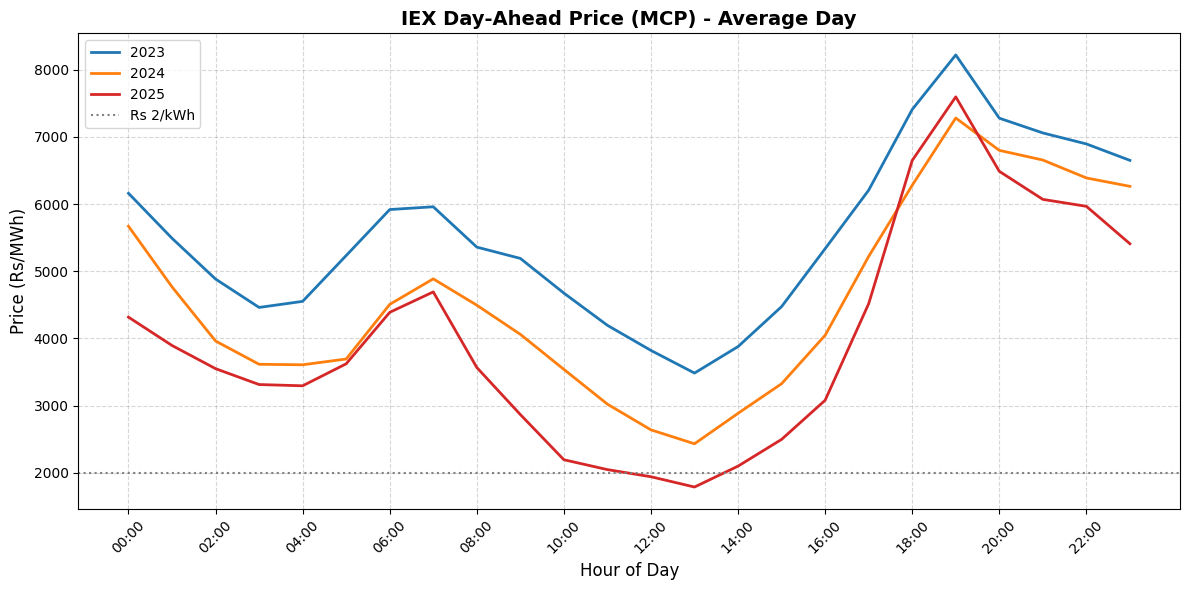

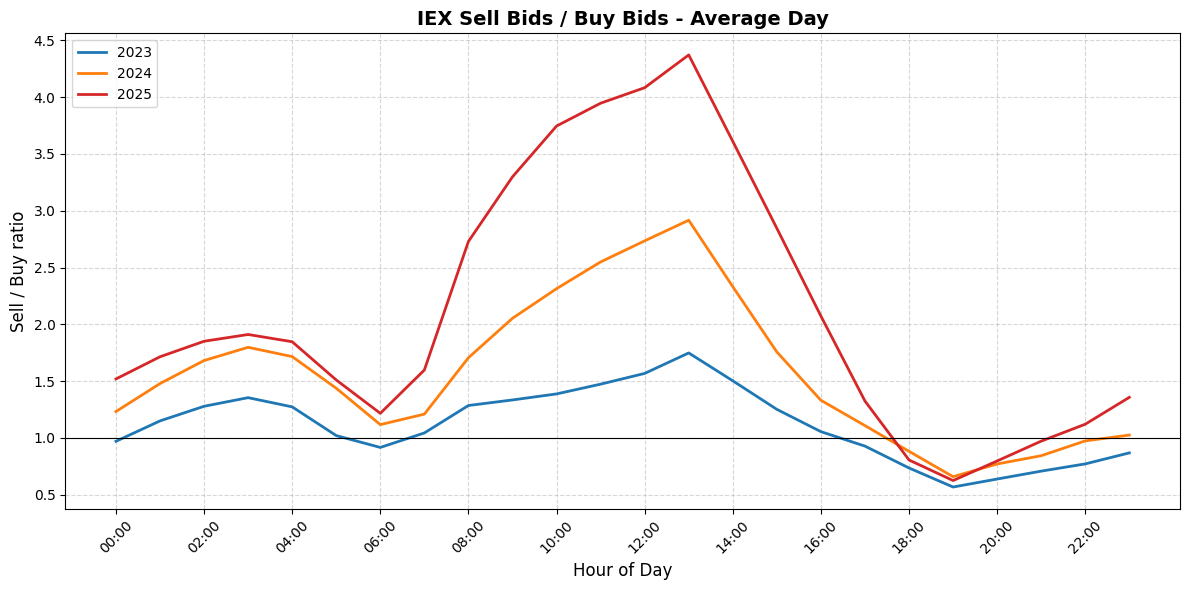

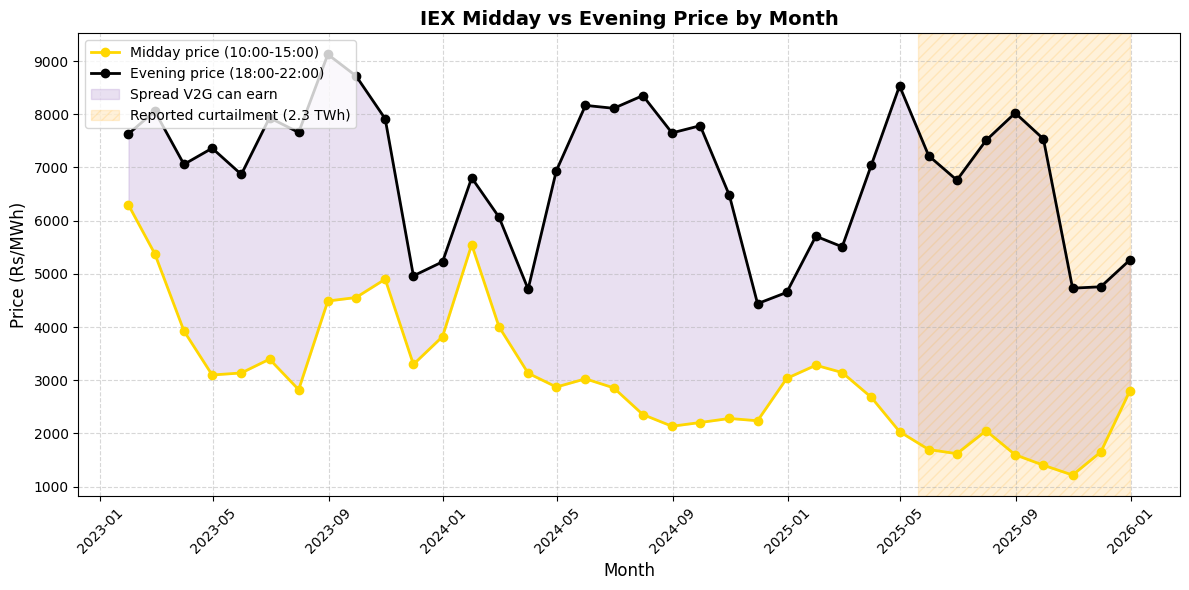

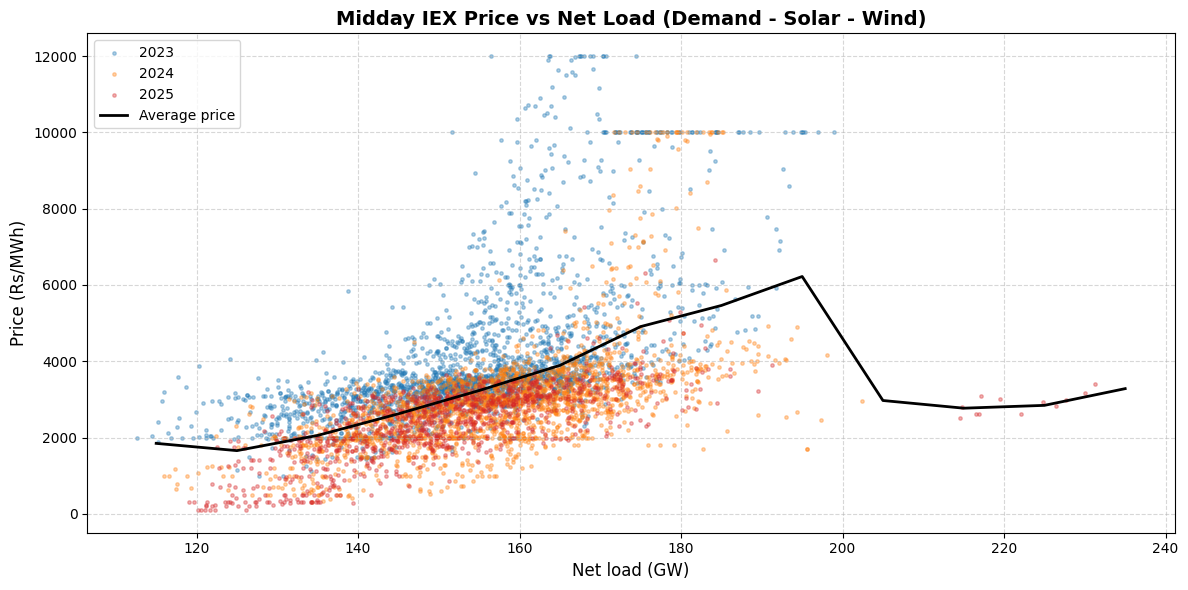

Yearly IEX indicators:
  year  avg_MCP  midday_MCP  evening_MCP  spread_evening_minus_midday  midday_hours_below_Rs2_pct  midday_hours_below_Rs1_pct  evening_hours_at_cap_pct  midday_sell_buy_ratio  evening_sell_buy_ratio  midday_sell_bid_GW  midday_buy_bid_GW
 2023  5533.04     4087.54      7372.63                      3285.10                        3.93                        0.05                     38.47                   1.49                    0.68               13.64              10.47
 2024  4585.00     2973.16      6681.37                      3708.22                       18.81                        3.37                     33.44                   2.43                    0.83               20.18               9.79
 2025  3993.43     2093.72      6554.22                      4460.50                       47.81                       12.65                     31.18                   3.77                    0.86               32.16              10.34

Midday price vs net load (C

In [4]:
# =====================================================================================
# CELL 3 - IEX Day-Ahead Market: evidence of midday solar surplus, 2023-2025
#   Surplus signals: very low midday clearing price (MCP), sell bids far above buy bids
#   V2G revenue signal: evening price minus midday price (the arbitrage spread)
#   Link to Cell 2: does the midday price fall when net load (demand - solar - wind) falls?
#   Outputs: results/03_*.csv, figures/03_*.png
# =====================================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm

BASE = os.path.abspath("."); RES = os.path.join(BASE, "results"); FIG = os.path.join(BASE, "figures")
iex = pd.read_csv(os.path.join(RES, "01_iex_hourly.csv"), parse_dates=["time"]).set_index("time")
grid = pd.read_csv(os.path.join(RES, "02_grid_hourly_clean.csv"), parse_dates=["time"]).set_index("time")
iex["year"] = iex.index.year; iex["month"] = iex.index.month; iex["hour"] = iex.index.hour
MID, EVE = iex.hour.between(10, 15), iex.hour.between(18, 22)          # solar hours / evening peak
CHEAP = 2000                                                             # Rs/MWh = Rs 2/kWh

# ---------------------------------------------------------------- 1. yearly + monthly indicators
rows = []
for y, d in tqdm(iex.groupby("year"), desc="IEX yearly indicators"):
    m, e = d[d.hour.between(10, 15)], d[d.hour.between(18, 22)]
    rows.append(dict(year=y, avg_MCP=d.mcp_rs_mwh.mean(), midday_MCP=m.mcp_rs_mwh.mean(), evening_MCP=e.mcp_rs_mwh.mean(),
                     spread_evening_minus_midday=e.mcp_rs_mwh.mean() - m.mcp_rs_mwh.mean(),
                     midday_hours_below_Rs2_pct=(m.mcp_rs_mwh < CHEAP).mean() * 100,
                     midday_hours_below_Rs1_pct=(m.mcp_rs_mwh < 1000).mean() * 100,
                     evening_hours_at_cap_pct=(e.mcp_rs_mwh >= 9990).mean() * 100,
                     midday_sell_buy_ratio=m.sell_buy_ratio.mean(), evening_sell_buy_ratio=e.sell_buy_ratio.mean(),
                     midday_sell_bid_GW=m.sell_bid_mw.mean() / 1e3, midday_buy_bid_GW=m.purchase_bid_mw.mean() / 1e3))
yearly = pd.DataFrame(rows).round(2); yearly.to_csv(os.path.join(RES, "03_iex_yearly_summary.csv"), index=False)

mon = iex.resample("ME").apply(lambda d: pd.Series({
    "midday_MCP": d.loc[d.hour.between(10, 15), "mcp_rs_mwh"].mean(),
    "evening_MCP": d.loc[d.hour.between(18, 22), "mcp_rs_mwh"].mean(),
    "midday_below_Rs2_pct": (d.loc[d.hour.between(10, 15), "mcp_rs_mwh"] < CHEAP).mean() * 100,
    "midday_sell_buy_ratio": d.loc[d.hour.between(10, 15), "sell_buy_ratio"].mean()}))
mon["spread"] = mon.evening_MCP - mon.midday_MCP
mon.round(2).to_csv(os.path.join(RES, "03_iex_monthly.csv"))
prof = iex.groupby(["year", "hour"])[["mcp_rs_mwh", "sell_buy_ratio"]].mean()
prof.to_csv(os.path.join(RES, "03_iex_hourly_profile_by_year.csv"))

# ---------------------------------------------------------------- 2. link to Cell 2 net load (overlap: 2023 - Jun 2025)
j = grid[["net_load", "demand", "solar"]].join(iex[["mcp_rs_mwh", "sell_buy_ratio", "hour"]], how="inner").dropna()
jm = j[j.hour.between(10, 15)]
corr = dict(hours=len(jm), corr_netload_vs_MCP=jm.net_load.corr(jm.mcp_rs_mwh),
            corr_netload_vs_sellbuy=jm.net_load.corr(jm.sell_buy_ratio),
            corr_solar_vs_MCP=jm.solar.corr(jm.mcp_rs_mwh))
bins = pd.cut(jm.net_load / 1e3, bins=np.arange(80, 241, 10))
binned = jm.groupby(bins, observed=True).agg(hours=("mcp_rs_mwh", "size"), mean_MCP=("mcp_rs_mwh", "mean"),
                                             share_below_Rs2_pct=("mcp_rs_mwh", lambda s: (s < CHEAP).mean() * 100))
binned.round(1).to_csv(os.path.join(RES, "03_midday_price_vs_net_load.csv"))
pd.Series(corr).round(3).to_csv(os.path.join(RES, "03_correlations.csv"), header=["value"])

# ---------------------------------------------------------------- 3. plots
hours = pd.date_range("2022-01-01 00:00", "2022-01-01 23:00", freq="h")
def plot_style(ax, title, ylabel, xlabel="Hour of Day", hour_axis=True):
    ax.set_title(title, fontsize=14, fontweight="bold"); ax.set_xlabel(xlabel, fontsize=12); ax.set_ylabel(ylabel, fontsize=12)
    if hour_axis:
        ax.set_xticks(hours[::2]); ax.set_xticklabels([h.strftime("%H:%M") for h in hours[::2]], rotation=45)
    ax.legend(loc="upper left", frameon=True); ax.grid(True, linestyle="--", alpha=0.5)
yrs = sorted(iex.year.unique()); col = dict(zip(yrs, ["tab:blue", "tab:orange", "tab:red"]))

fig, ax = plt.subplots(figsize=(12, 6))
for y in yrs: ax.plot(hours, prof.loc[y, "mcp_rs_mwh"].values, color=col[y], linewidth=2, label=f"{y}")
ax.axhline(CHEAP, color="gray", linestyle=":", label="Rs 2/kWh")
plot_style(ax, "IEX Day-Ahead Price (MCP) - Average Day", "Price (Rs/MWh)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03a_iex_price_by_hour.png")); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
for y in yrs: ax.plot(hours, prof.loc[y, "sell_buy_ratio"].values, color=col[y], linewidth=2, label=f"{y}")
ax.axhline(1, color="black", linewidth=0.8)
plot_style(ax, "IEX Sell Bids / Buy Bids - Average Day", "Sell / Buy ratio")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03b_iex_sell_buy_by_hour.png")); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(mon.index, mon.midday_MCP, color="gold", linewidth=2, marker="o", label="Midday price (10:00-15:00)")
ax.plot(mon.index, mon.evening_MCP, color="black", linewidth=2, marker="o", label="Evening price (18:00-22:00)")
ax.fill_between(mon.index, mon.midday_MCP, mon.evening_MCP, color="tab:purple", alpha=0.2, label="Spread V2G can earn")
ax.axvspan(pd.Timestamp("2025-05-20"), pd.Timestamp("2025-12-31"), color="orange", alpha=0.15, hatch="///",
           label="Reported curtailment (2.3 TWh)")
plot_style(ax, "IEX Midday vs Evening Price by Month", "Price (Rs/MWh)", xlabel="Month", hour_axis=False)
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(os.path.join(FIG, "03c_iex_monthly_spread.png")); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
for y in sorted(jm.index.year.unique()):
    d = jm[jm.index.year == y]; ax.scatter(d.net_load / 1e3, d.mcp_rs_mwh, s=6, alpha=0.35, color=col.get(y, "gray"), label=f"{y}")
ax.plot([b.mid for b in binned.index], binned.mean_MCP, color="black", linewidth=2, label="Average price")
plot_style(ax, "Midday IEX Price vs Net Load (Demand - Solar - Wind)", "Price (Rs/MWh)", xlabel="Net load (GW)", hour_axis=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03d_price_vs_net_load.png")); plt.show()

pd.set_option("display.width", 220)
print("Yearly IEX indicators:\n", yearly.to_string(index=False))
print("\nMidday price vs net load (Cell 2 overlap):", {k: round(v, 3) for k, v in corr.items()})
print("\nMidday price by net-load band:\n", binned.round(0).to_string())


**Cell 4:** how much solar *had* to be curtailed each year. Daily least-cost dispatch with coal minimum load, calibrated to India's reported Apr–Jun 2026 curtailment (8,133 GWh), then run for every day of 2022 – Jun 2025. Defines `solve_day()`, which later cells reuse.

Worst-day charts:   0%|          | 0/4 [00:00<?, ?it/s]                                        

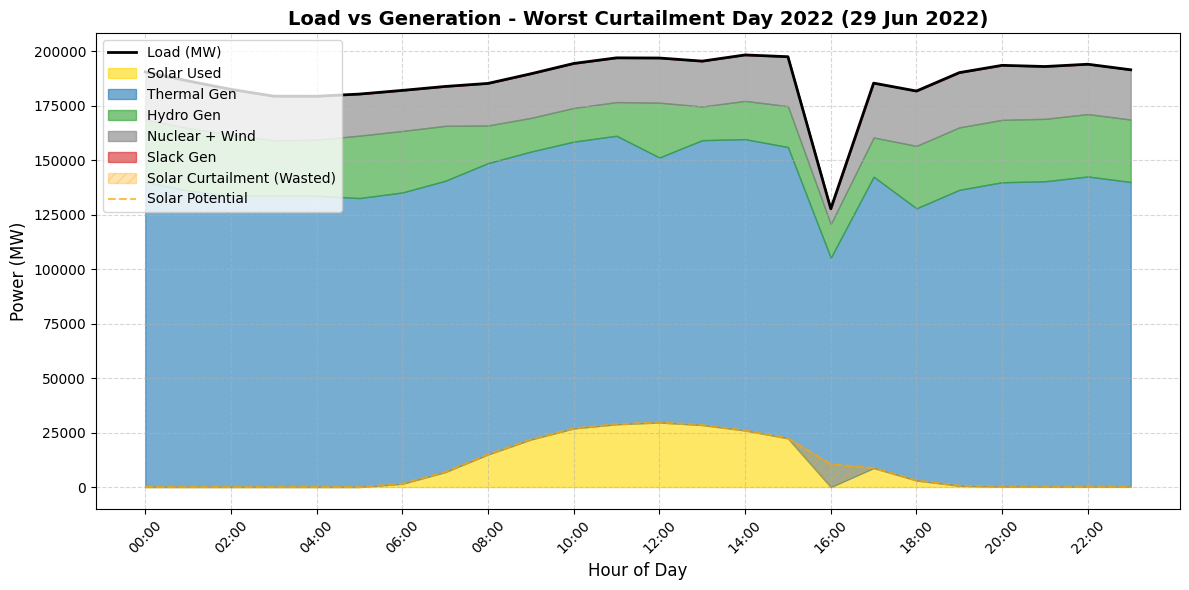

Worst-day charts:  25%|██▌       | 1/4 [00:00<00:00,  4.41it/s]

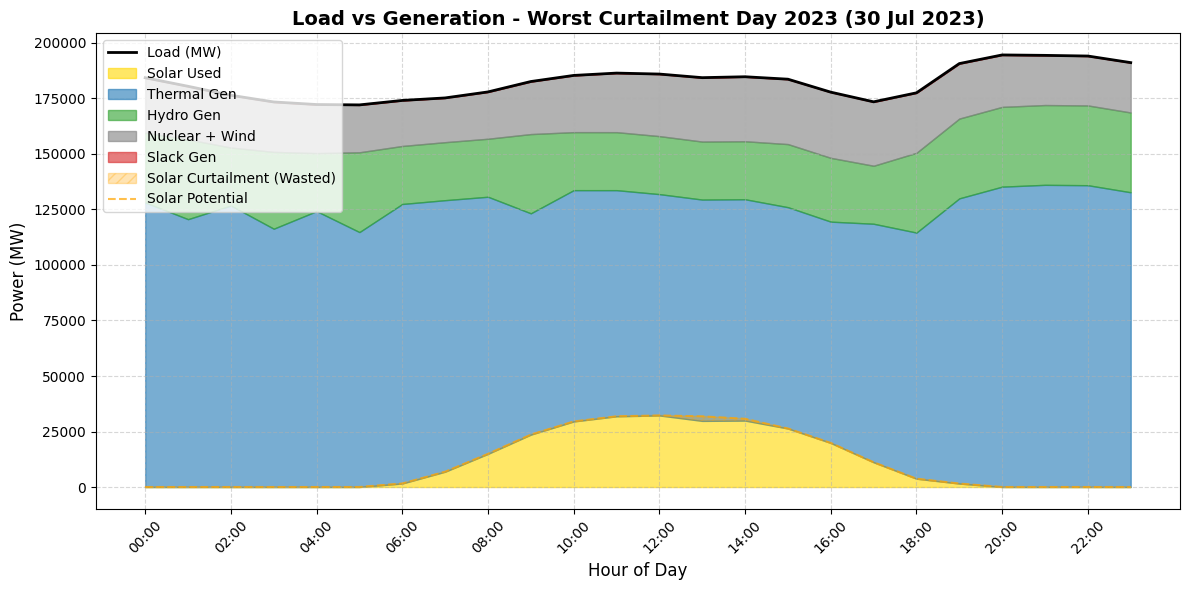

Worst-day charts:  50%|█████     | 2/4 [00:00<00:00,  4.51it/s]

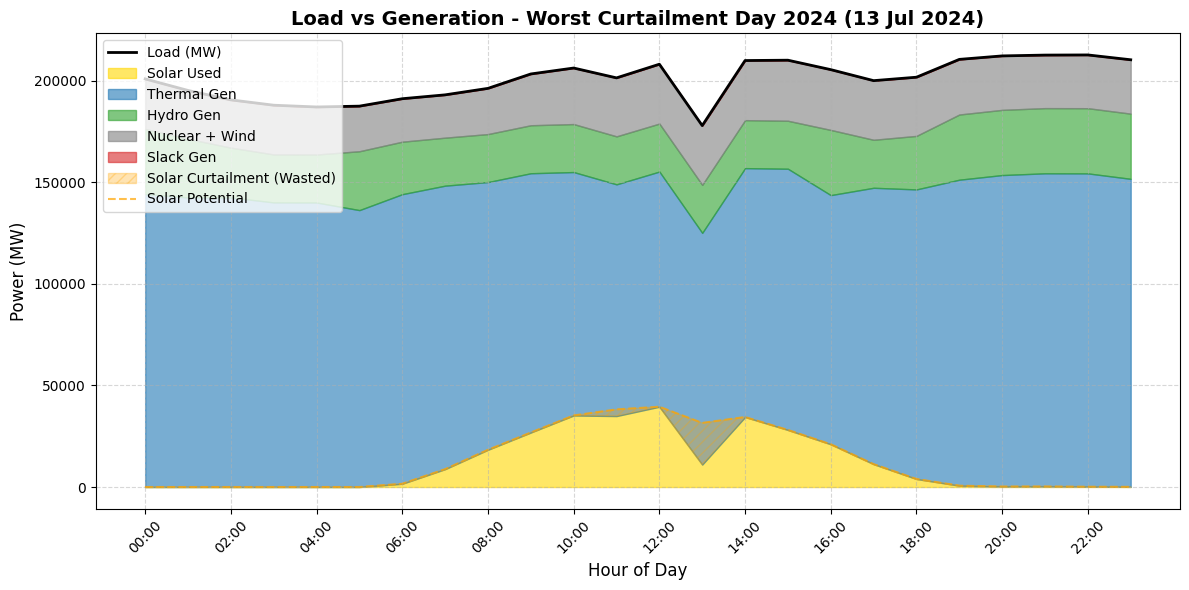

Worst-day charts:  75%|███████▌  | 3/4 [00:00<00:00,  4.74it/s]

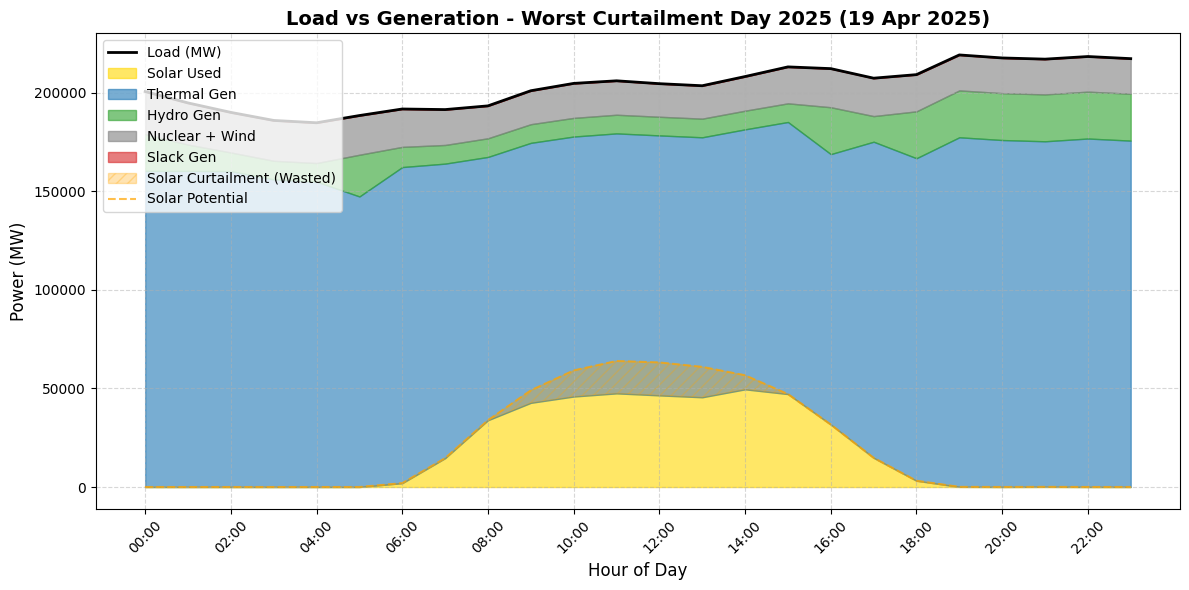

Worst-day charts: 100%|██████████| 4/4 [00:00<00:00,  4.72it/s]


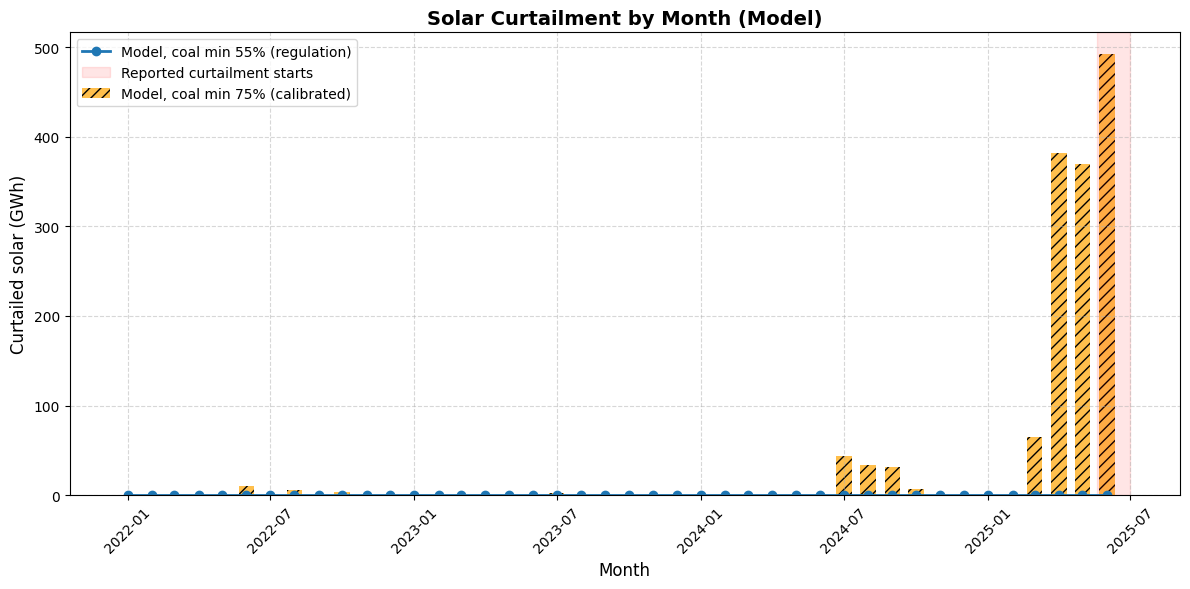

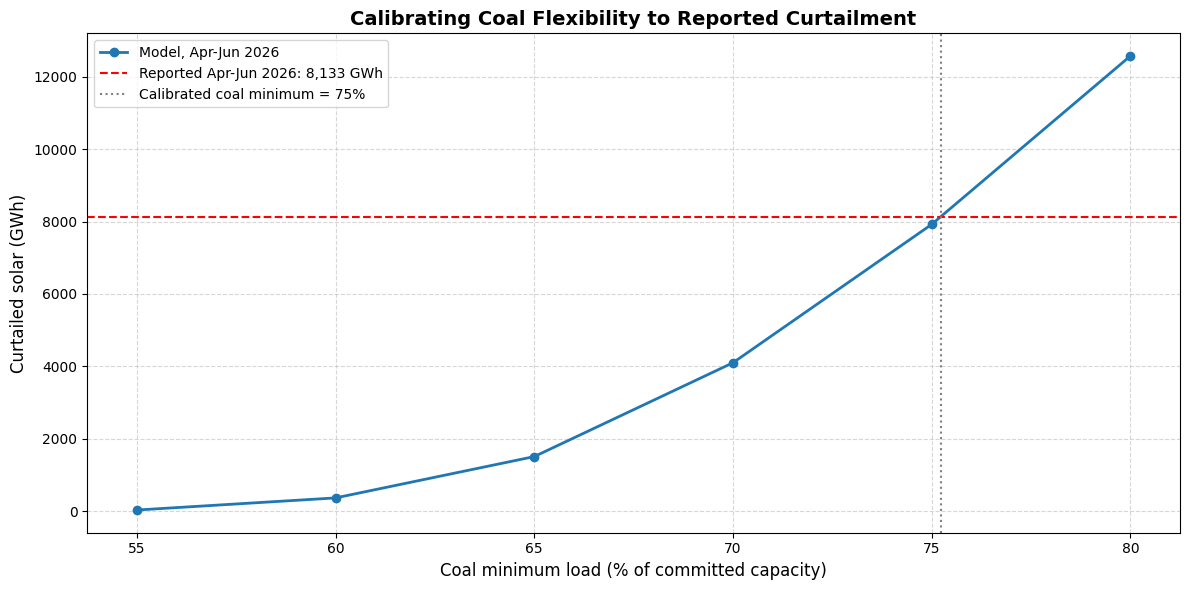

Calibration (Apr-Jun 2026):
  tml  model_GWh_AprJun2026  days
0.55                  30.0    84
0.60                 365.0    84
0.65                1506.0    84
0.70                4098.0    84
0.75                7920.0    84
0.80               12572.0    84 
-> calibrated coal minimum load = 0.752

Yearly curtailment (model):
       days  curtail_GWh  curtail_GWh_55pct  days_with_curtailment  worst_day_GWh  lowest_midday_net_load_GW  avg_coal_committed_GW  curtail_pct_of_solar
year                                                                                                                                                    
2022   352         19.8                0.0                      5           10.5                       98.3                  134.8                   0.0
2023   363          2.9                0.0                      1            2.9                      112.6                  149.3                   0.0
2024   347        115.9                0.0               

In [5]:
# =====================================================================================
# CELL 4 - How much solar HAD to be curtailed each year? (daily least-cost dispatch)
#   For every day: meet hourly demand at least cost with solar, wind, nuclear (must-run), hydro (daily
#   energy budget, minimum flow), coal in 3 merit-order tranches and gas. Coal that is switched on for the
#   evening peak cannot go below its minimum technical load (TML) at noon -> surplus solar is curtailed.
#   Step A: calibrate TML so the model reproduces India's reported curtailment in Apr-Jun 2026 (8,133 GWh),
#           using Apr-Jun 2025 weather/demand scaled to 2026 solar capacity and demand.
#   Step B: run every day of 2022 - Jun 2025 with that TML -> curtailment by month and year.
#   Check:  2022-2024 should be ~0 (no curtailment reported); onset should appear from late May 2025.
#   The dispatch function solve_day() is reused by later cells (run this cell before them).
#   Outputs: results/04_*.csv, figures/04_*.png
# =====================================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy.sparse as sp
from scipy.optimize import linprog
from tqdm.auto import tqdm

BASE = os.path.abspath("."); RES = os.path.join(BASE, "results"); FIG = os.path.join(BASE, "figures")
g = pd.read_csv(os.path.join(RES, "02_grid_hourly_clean.csv"), parse_dates=["time"]).set_index("time")
T = 24; HRS = np.arange(T)

# ---------------------------------------------------------------- inputs
COAL_TRANCHES = [(0.50, 2200), (0.35, 3200), (0.15, 5000)]    # share of coal fleet, variable cost Rs/MWh (merit order)
COAL_MAX, GAS_MW = 230e3, 12e3                                  # MW available
COST = dict(gas=8000, hydro=500, shortage=10000, commit=5, storage=100)
ACTUAL_AMJ_2026 = 8133                                          # GWh solar curtailed Apr-Jun 2026 (MoP, Rajya Sabha)
CAP_END_2025, CAP_END_JUN_2026 = 133.5e3, 159.5e3               # MW: 168 GW Aug-2026 minus 2026 installs; +26 GW in H1 2026
DEMAND_2026 = 256.1 / 241.4                                     # Apr-Jun peak demand 2026 vs 2025
WIND_2026, NUC_2026, HYD_2026 = 1.10, 1.08, 1.02
TML_GRID = [0.55, 0.60, 0.65, 0.70, 0.75, 0.80]

# hydro & nuclear are only measured to Dec 2023 -> later days use the same calendar month of 2022-2023
d23 = g[g.index.year.isin([2022, 2023])].copy(); d23["day"] = d23.index.normalize()
daily = d23.groupby("day").agg(h_min=("hydro", "min"), h_max=("hydro", "max"), h_e=("hydro", "sum"), nuc=("nuclear", "mean"))
hyd_month = daily.groupby(daily.index.month).median()
NUC_GROWTH = {2022: 1.0, 2023: 1.0, 2024: 1.09, 2025: 1.17}     # installed nuclear ~6.8 -> 8.8 GW

def day_inputs(date, solar_scale=1.0, demand_scale=1.0, wind_scale=1.0, nuc_scale=1.0, hyd_scale=1.0):
    x = g.loc[str(date.date())]
    if len(x) != 24 or x["demand"].isna().any() or x["solar"].isna().any(): return None
    has_mix = x["hydro"].notna().all() and x["nuclear"].notna().all()
    hm = hyd_month.loc[date.month]
    h_min, h_max, h_e = (x.hydro.min(), x.hydro.max(), x.hydro.sum()) if has_mix else (hm.h_min, hm.h_max, hm.h_e)
    nuc = x.nuclear.values if has_mix else np.full(24, hm.nuc * NUC_GROWTH.get(date.year, 1.17) / NUC_GROWTH.get(2023))
    return dict(demand=x.demand.values * demand_scale, solar=x.solar.values * solar_scale, wind=x.wind.fillna(0).values * wind_scale,
                nuclear=nuc * nuc_scale, h_min=h_min * hyd_scale, h_max=h_max * hyd_scale, h_e=h_e * hyd_scale)

# ---------------------------------------------------------------- daily dispatch LP (reused by later cells)
NAMES = ["solar", "wind", "hydro", "coal1", "coal2", "coal3", "gas", "shortage",
         "st_ch", "st_dis", "st_soc", "ev_ch", "ev_dis", "ev_soc"]
IX = {k: np.arange(T) + i * T for i, k in enumerate(NAMES)}
NC = len(NAMES) * T; COMMIT = [NC, NC + 1, NC + 2]; NV = NC + 3

def solve_day(day, tml, storage=(0, 0), ev=None):
    """day: dict from day_inputs. storage: (MW, MWh) grid batteries. ev: dict(n, case, avail, drive, batt_kwh,
    charger_kw, eff, soc_min, deg) for V1G/V2G fleets (used in later cells)."""
    net = day["demand"] - day["nuclear"]
    lb, ub, c = np.zeros(NV), np.zeros(NV), np.zeros(NV)
    ub[IX["solar"]] = day["solar"]; ub[IX["wind"]] = day["wind"]
    lb[IX["hydro"]] = min(day["h_min"], day["h_max"]); ub[IX["hydro"]] = day["h_max"]; c[IX["hydro"]] = COST["hydro"]
    for k, (share, cost) in enumerate(COAL_TRANCHES):
        ub[IX[f"coal{k+1}"]] = COAL_MAX * share; c[IX[f"coal{k+1}"]] = cost
        ub[COMMIT[k]] = COAL_MAX * share; c[COMMIT[k]] = COST["commit"]
    ub[IX["gas"]] = GAS_MW; c[IX["gas"]] = COST["gas"]; ub[IX["shortage"]] = 1e6; c[IX["shortage"]] = COST["shortage"]
    Pb, Eb = storage; ub[IX["st_ch"]] = Pb; ub[IX["st_dis"]] = Pb; ub[IX["st_soc"]] = Eb; c[IX["st_dis"]] = COST["storage"]
    ev_on = ev is not None and ev["n"] > 0 and ev["case"] in ("v1g", "v2g")
    if ev is not None and ev["n"] > 0 and ev["case"] == "unmanaged":
        net = net + ev["unmanaged_profile"] * ev["n"] * ev["drive_kwh"] / 1e3 / ev["eff"]
    if ev_on:
        P = ev["n"] * ev["charger_kw"] / 1e3; E = ev["n"] * ev["batt_kwh"] / 1e3
        ub[IX["ev_ch"]] = P * ev["avail"]; ub[IX["ev_dis"]] = P * ev["avail"] if ev["case"] == "v2g" else 0
        lb[IX["ev_soc"]] = ev["soc_min"] * E; ub[IX["ev_soc"]] = E; c[IX["ev_dis"]] = ev["deg"] / ev["eff"]
        drive = ev["drive_profile"] * ev["n"] * ev["drive_kwh"] / 1e3
    I = sp.identity(T, format="csr"); Z = sp.csr_matrix((T, T))
    shift = sp.csr_matrix((np.ones(T), (HRS, (HRS - 1) % T)), shape=(T, T))
    row = lambda **b: sp.hstack([b.get(k, Z) for k in NAMES] + [sp.csr_matrix((T, NV - NC))], format="csr")
    A_eq = [row(solar=I, wind=I, hydro=I, coal1=I, coal2=I, coal3=I, gas=I, shortage=I, st_ch=-I, st_dis=I, ev_ch=-I, ev_dis=I),
            row(st_soc=I - shift, st_ch=-0.92 * I, st_dis=I / 0.92)]
    b_eq = [net, np.zeros(T)]
    if ev_on:
        A_eq.append(row(ev_soc=I - shift, ev_ch=-ev["eff"] * I, ev_dis=I / ev["eff"])); b_eq.append(-drive)
    else:
        A_eq.append(row(ev_soc=I)); b_eq.append(np.zeros(T))
    A_ub, b_ub = [], []
    for k in range(3):
        col = sp.csr_matrix((np.ones(T), (HRS, np.full(T, COMMIT[k]))), shape=(T, NV))
        A_ub += [row(**{f"coal{k+1}": I}) - col, -row(**{f"coal{k+1}": I}) + tml * col]; b_ub += [np.zeros(T), np.zeros(T)]
    A_ub.append(sp.csr_matrix(np.isin(np.arange(NV), IX["hydro"]).astype(float))); b_ub.append([max(day["h_e"], day["h_min"] * 24)])
    if ev_on:
        A_ub.append(row(ev_ch=I, ev_dis=I)); b_ub.append(P * ev["avail"])
    r = linprog(c, A_ub=sp.vstack(A_ub), b_ub=np.concatenate(b_ub), A_eq=sp.vstack(A_eq), b_eq=np.concatenate(b_eq),
                bounds=np.c_[lb, ub], method="highs")
    if r.status != 0: raise RuntimeError(r.message)
    x = {k: r.x[IX[k]] for k in NAMES}; x["coal"] = x["coal1"] + x["coal2"] + x["coal3"]
    op = sum(x[f"coal{k+1}"].sum() * cst for k, (_, cst) in enumerate(COAL_TRANCHES)) + x["gas"].sum() * COST["gas"] \
        + x["hydro"].sum() * COST["hydro"] + x["shortage"].sum() * COST["shortage"] + x["st_dis"].sum() * COST["storage"] \
        + r.x[COMMIT].sum() * COST["commit"]
    x.update(solar_potential=day["solar"], demand=day["demand"], nuclear=day["nuclear"],
             curtail=(day["solar"] - x["solar"]).clip(0), op_cost=op, coal_commit=r.x[COMMIT].sum(),
             deg_cost=(x["ev_dis"].sum() / ev["eff"] * ev["deg"]) if ev_on else 0.0)
    return x

def run_days(dates, tml, desc=None, keep_ts=False, **scale):
    out, ts = [], {}
    for d in tqdm(dates, desc=desc, leave=False):
        day = day_inputs(d, **scale)
        if day is None: continue
        x = solve_day(day, tml)
        out.append(dict(date=d, curtail_mwh=x["curtail"].sum(), solar_avail_mwh=day["solar"].sum(),
                        coal_mwh=x["coal"].sum(), coal_commit_mw=x["coal_commit"], shortage_mwh=x["shortage"].sum(),
                        midday_min_net_load=(day["demand"] - day["solar"] - day["wind"])[10:16].min()))
        if keep_ts: ts[d] = x
    return (pd.DataFrame(out).set_index("date"), ts) if keep_ts else pd.DataFrame(out).set_index("date")

# ---------------------------------------------------------------- Step A: calibrate TML on Apr-Jun 2026
amj25 = pd.date_range("2025-04-01", "2025-06-24")
cap_now = g["solar_cap_mw"]
cal = []
for tml in tqdm(TML_GRID, desc="A. Calibrating coal minimum load on Apr-Jun 2026"):
    tot, days = 0.0, 0
    for d in amj25:
        frac = (d.dayofyear - 1) / 181                              # position in H1 -> 2026 capacity on the same date
        cap26 = CAP_END_2025 + frac * (CAP_END_JUN_2026 - CAP_END_2025)
        day = day_inputs(d, solar_scale=cap26 / cap_now.loc[str(d.date())].iloc[0], demand_scale=DEMAND_2026,
                         wind_scale=WIND_2026, nuc_scale=NUC_2026, hyd_scale=HYD_2026)
        if day is None: continue
        tot += solve_day(day, tml)["curtail"].sum(); days += 1
    cal.append(dict(tml=tml, model_GWh_AprJun2026=tot / 1e3 * 91 / days, days=days))   # scale to the full 91 days
cal = pd.DataFrame(cal)
TML = float(np.interp(ACTUAL_AMJ_2026, cal.model_GWh_AprJun2026, cal.tml)) if cal.model_GWh_AprJun2026.max() >= ACTUAL_AMJ_2026 else cal.tml.max()
cal.round(3).to_csv(os.path.join(RES, "04_calibration_tml.csv"), index=False)

# ---------------------------------------------------------------- Step B: every day 2022 - Jun 2025
dates = pd.date_range("2022-01-01", "2025-06-24")
runs = {}
for tml, lab in [(TML, "calibrated"), (0.55, "55% (regulation)")]:
    if lab == "calibrated":
        runs[lab], ts_cal = run_days(dates, tml, desc=f"B. Daily dispatch 2022-2025, coal min {tml:.0%}", keep_ts=True)
    else:
        runs[lab] = run_days(dates, tml, desc=f"B. Daily dispatch 2022-2025, coal min {tml:.0%}")
res = runs["calibrated"].join(runs["55% (regulation)"][["curtail_mwh"]].rename(columns={"curtail_mwh": "curtail_mwh_55pct"}))
res.to_csv(os.path.join(RES, "04_daily_curtailment.csv"))
res["year"] = res.index.year; res["month"] = res.index.to_period("M")
monthly = res.groupby("month").agg(curtail_GWh=("curtail_mwh", lambda s: s.sum() / 1e3),
                                   curtail_GWh_55pct=("curtail_mwh_55pct", lambda s: s.sum() / 1e3),
                                   days_with_curtailment=("curtail_mwh", lambda s: (s > 1).sum()),
                                   solar_avail_TWh=("solar_avail_mwh", lambda s: s.sum() / 1e6))
monthly.round(2).to_csv(os.path.join(RES, "04_monthly_curtailment.csv"))
yearly = res.groupby("year").agg(days=("curtail_mwh", "size"), curtail_GWh=("curtail_mwh", lambda s: s.sum() / 1e3),
                                 curtail_GWh_55pct=("curtail_mwh_55pct", lambda s: s.sum() / 1e3),
                                 days_with_curtailment=("curtail_mwh", lambda s: (s > 1).sum()),
                                 worst_day_GWh=("curtail_mwh", lambda s: s.max() / 1e3),
                                 lowest_midday_net_load_GW=("midday_min_net_load", lambda s: s.min() / 1e3),
                                 avg_coal_committed_GW=("coal_commit_mw", lambda s: s.mean() / 1e3))
yearly["curtail_pct_of_solar"] = yearly.curtail_GWh / (res.groupby("year").solar_avail_mwh.sum() / 1e3) * 100
yearly.round(2).to_csv(os.path.join(RES, "04_yearly_curtailment.csv"))

# ---------------------------------------------------------------- plots
hours = pd.date_range("2022-01-01 00:00", "2022-01-01 23:00", freq="h")
def plot_style(ax, title, ylabel="Power (MW)", xlabel="Hour of Day", hour_axis=True):
    ax.set_title(title, fontsize=14, fontweight="bold"); ax.set_xlabel(xlabel, fontsize=12); ax.set_ylabel(ylabel, fontsize=12)
    if hour_axis: ax.set_xticks(hours[::2]); ax.set_xticklabels([h.strftime("%H:%M") for h in hours[::2]], rotation=45)
    ax.legend(loc="upper left", frameon=True); ax.grid(True, linestyle="--", alpha=0.5)

def load_vs_generation(x, title, fname):
    fig, ax = plt.subplots(figsize=(12, 6))
    load = x["demand"]; solar, thermal, hydro = x["solar"], x["coal"] + x["gas"], x["hydro"]
    other = x["nuclear"] + x["wind"]; slack = x["shortage"]
    ax.plot(hours, load, label="Load (MW)", color="black", linewidth=2, zorder=3)
    ax.fill_between(hours, 0, solar, label="Solar Used", alpha=0.6, color="gold")
    ax.fill_between(hours, solar, solar + thermal, label="Thermal Gen", alpha=0.6, color="tab:blue")
    ax.fill_between(hours, solar + thermal, solar + thermal + hydro, label="Hydro Gen", alpha=0.6, color="tab:green")
    ax.fill_between(hours, solar + thermal + hydro, solar + thermal + hydro + other, label="Nuclear + Wind", alpha=0.6, color="tab:gray")
    ax.fill_between(hours, solar + thermal + hydro + other, solar + thermal + hydro + other + slack, label="Slack Gen", alpha=0.6, color="tab:red")
    ax.fill_between(hours, solar, x["solar_potential"], color="orange", alpha=0.3, hatch="///", label="Solar Curtailment (Wasted)")
    ax.plot(hours, x["solar_potential"], linestyle="--", color="orange", alpha=0.7, label="Solar Potential")
    plot_style(ax, title); plt.tight_layout(); plt.savefig(os.path.join(FIG, fname)); plt.show()

for y in tqdm(sorted(res.year.unique()), desc="Worst-day charts"):
    worst = res[res.year == y].curtail_mwh.idxmax()
    load_vs_generation(ts_cal[worst], f"Load vs Generation - Worst Curtailment Day {y} ({worst:%d %b %Y})",
                       f"04a_load_vs_generation_worst_{y}.png")

fig, ax = plt.subplots(figsize=(12, 6))
mx = monthly.index.to_timestamp()
ax.bar(mx, monthly.curtail_GWh, width=20, color="orange", alpha=0.7, hatch="///", label=f"Model, coal min {TML:.0%} (calibrated)")
ax.plot(mx, monthly.curtail_GWh_55pct, color="tab:blue", marker="o", linewidth=2, label="Model, coal min 55% (regulation)")
ax.axvspan(pd.Timestamp("2025-05-20"), pd.Timestamp("2025-06-30"), color="red", alpha=0.1, label="Reported curtailment starts")
plot_style(ax, "Solar Curtailment by Month (Model)", ylabel="Curtailed solar (GWh)", xlabel="Month", hour_axis=False)
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(os.path.join(FIG, "04b_monthly_curtailment.png")); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cal.tml * 100, cal.model_GWh_AprJun2026, color="tab:blue", marker="o", linewidth=2, label="Model, Apr-Jun 2026")
ax.axhline(ACTUAL_AMJ_2026, color="red", linestyle="--", label="Reported Apr-Jun 2026: 8,133 GWh")
ax.axvline(TML * 100, color="gray", linestyle=":", label=f"Calibrated coal minimum = {TML:.0%}")
plot_style(ax, "Calibrating Coal Flexibility to Reported Curtailment", ylabel="Curtailed solar (GWh)",
          xlabel="Coal minimum load (% of committed capacity)", hour_axis=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04c_calibration.png")); plt.show()

pd.set_option("display.width", 220)
print("Calibration (Apr-Jun 2026):\n", cal.round({"tml": 2, "model_GWh_AprJun2026": 0}).to_string(index=False), f"\n-> calibrated coal minimum load = {TML:.3f}")
print("\nYearly curtailment (model):\n", yearly.round(1).to_string())
print("\nLast 8 months:\n", monthly.tail(8).round(1).to_string())


**Cell 5:** projection 2026–2030 (latest 12 months of data scaled to each year's solar, wind and demand), with and without CEA's planned grid storage, and an EV fleet doing smart charging (V1G) vs V2G. Run Cell 4 first in the same session. Takes ~5 minutes.

Projection years: 100%|██████████| 5/5 [02:42<00:00, 32.53s/it]


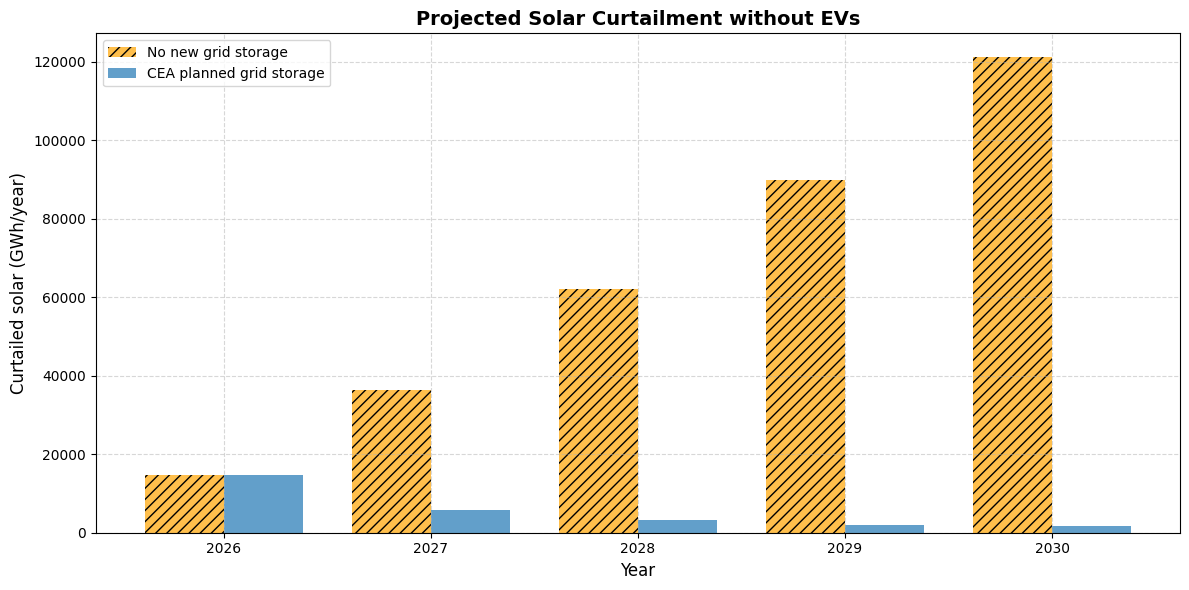

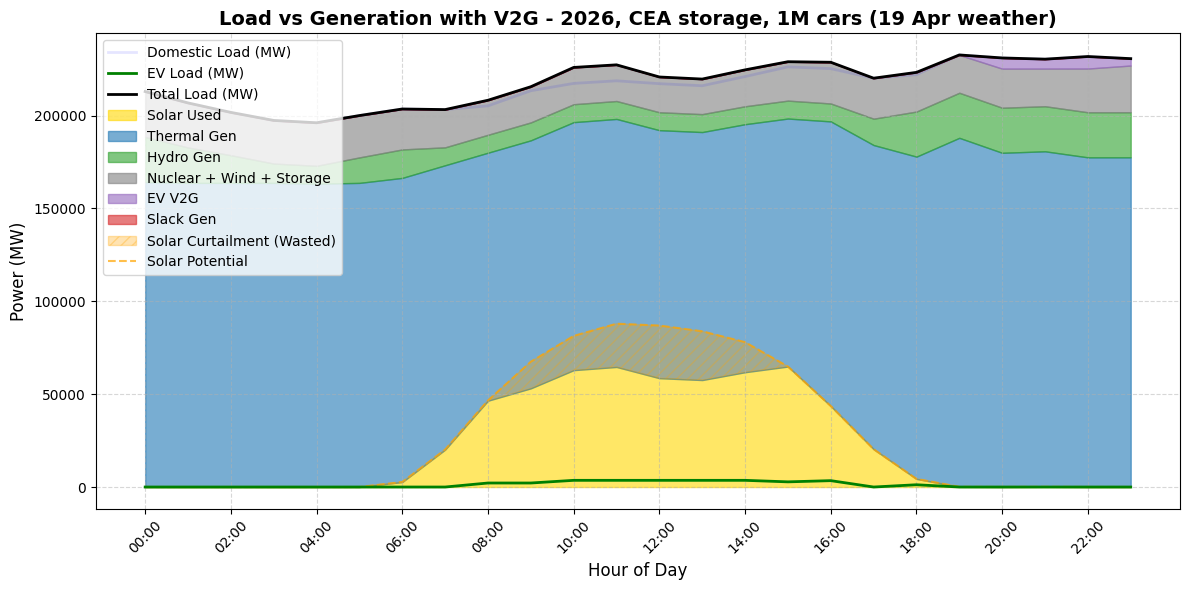

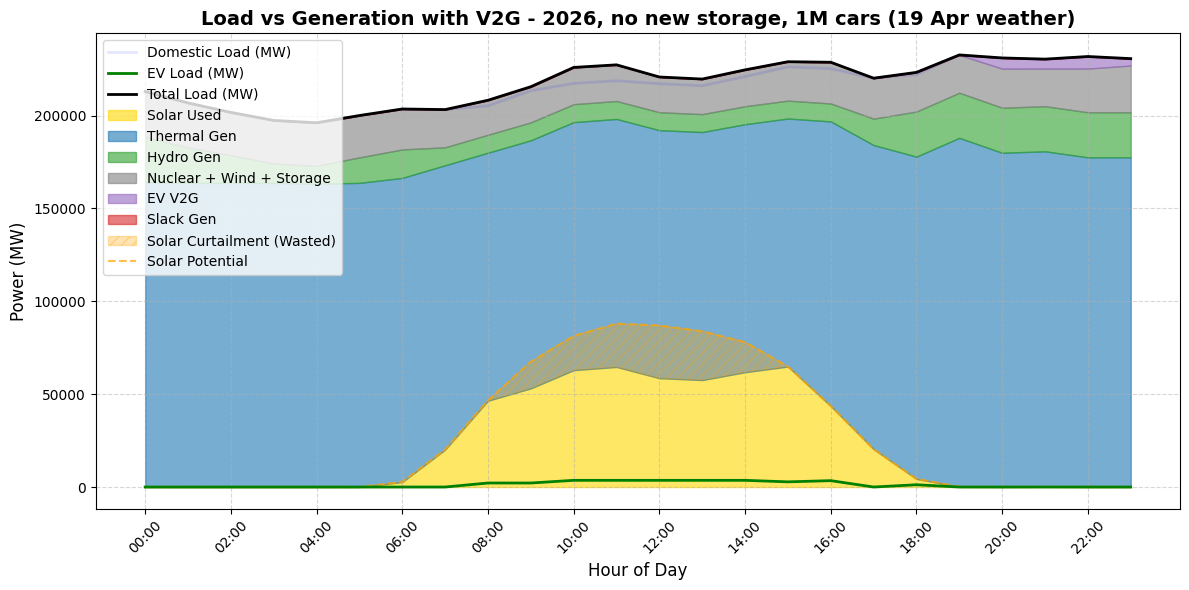

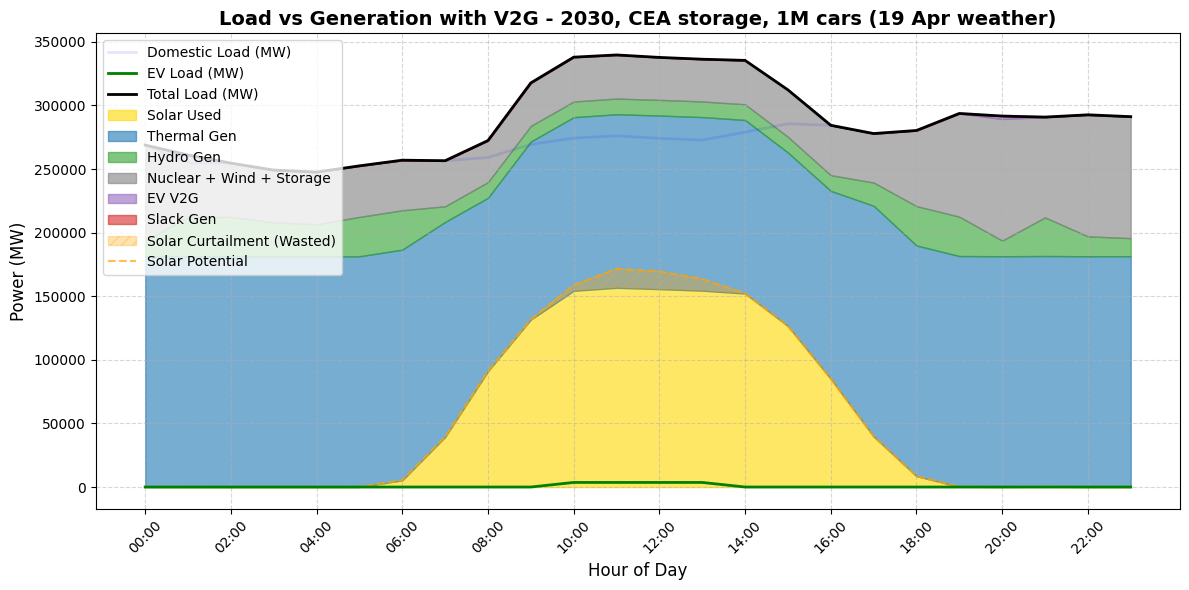

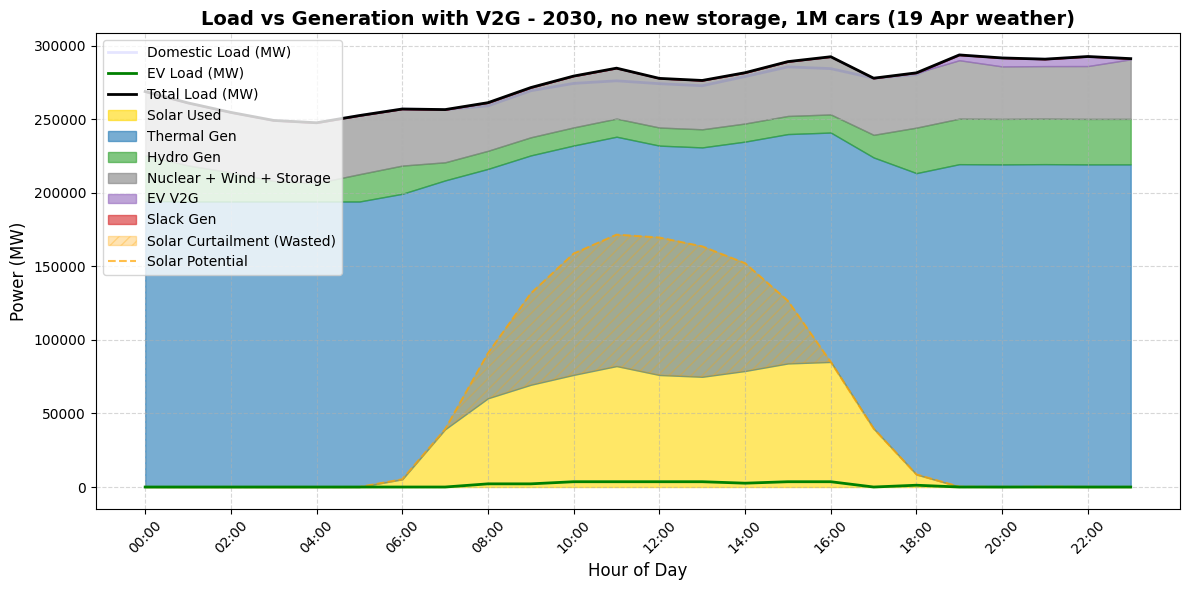

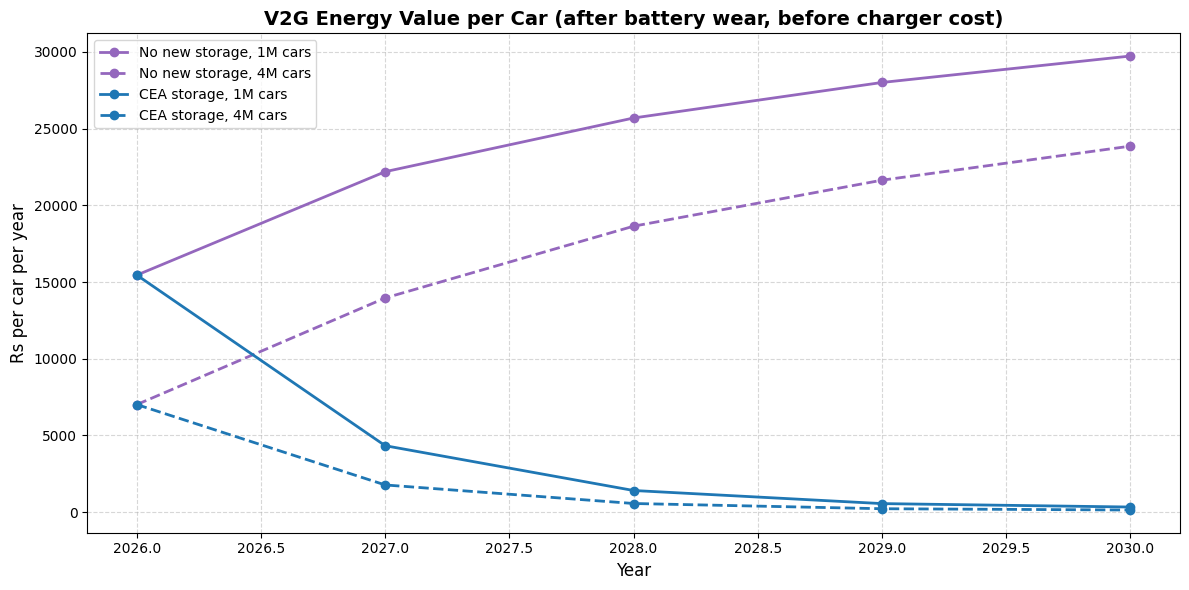

Projection without EVs:
  year storage  solar_GW  peak_demand_GW  storage_GW  storage_GWh  solar_avail_TWh  curtail_GWh  curtail_pct  coal_TWh  shortage_GWh  system_cost_cr
 2026 planned     150.0           256.1         5.0         10.0            208.9      14639.0          7.0    1286.3          16.2        324147.6
 2026    none     150.0           256.1         5.0         10.0            208.9      14639.0          7.0    1286.3          16.2        324147.6
 2027 planned     185.0           271.5        18.8         96.0            257.7       5768.8          2.2    1308.6           2.8        321784.4
 2027    none     185.0           271.5         5.0         10.0            257.7      36283.4         14.1    1328.7         105.4        335000.2
 2028 planned     220.0           287.8        32.5        182.0            306.5       3196.5          1.0    1339.2           0.0        324454.5
 2028    none     220.0           287.8         5.0         10.0            306.5      

In [6]:
# =====================================================================================
# CELL 5 - Projection 2026-2030: curtailment without EVs, and what an EV fleet does with V1G vs V2G
#   Needs Cell 4 run first in this session (reuses g, day_inputs, solve_day, TML).
#   Base year: latest 12 months of data (Jul 2024 - Jun 2025), scaled to each future year:
#     solar  : 150 GW (2026) -> 292.6 GW (2030, CEA plan)      wind : 55 -> 99.9 GW
#     demand : 256.1 GW peak in 2026, +6%/yr                    coal fleet grows with demand
#     grid storage: "planned" = CEA path to 41.65 GW/208 GWh BESS + 18.2 GW pumped storage by 2030,
#                   "none"    = only today's ~5 GW / 10 GWh
#   EV fleet (participating cars): 30 kWh battery, 7.2 kW charger, 4.5 kWh/day driving, 92% efficiency each way,
#     never below 20% charge, plug-in availability by hour (90% night, ~50% day). Battery wear charged in dispatch
#     at Rs 2,500/MWh from battery (LFP) so the fleet only cycles when it pays.
#   Cases: V1G = smart charging only; V2G = smart charging + export. Value of V2G = cost(V1G) - cost(V2G).
#   Outputs: results/05_*.csv (physical + Rs system cost; feasibility maths done in chat), figures/05_*.png
# =====================================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm

BASE_DATES = pd.date_range("2024-07-01", "2025-06-24")
YEARS = [2026, 2027, 2028, 2029, 2030]
SOLAR_GW = {2026: 150, 2027: 185, 2028: 220, 2029: 255, 2030: 292.6}           # year-average installed
WIND_GW = {2026: 55, 2027: 66, 2028: 77, 2029: 88, 2030: 99.9}
PEAK_GW = {y: 256.1 * 1.06 ** (y - 2026) for y in YEARS}
NUC_X = {2026: 1.10, 2027: 1.25, 2028: 1.40, 2029: 1.60, 2030: 1.80}
HYD_X = {2026: 1.02, 2027: 1.08, 2028: 1.15, 2029: 1.22, 2030: 1.30}
STORAGE = {"planned": {y: (5e3 + (60e3 - 5e3) * (y - 2026) / 4, 10e3 + (354e3 - 10e3) * (y - 2026) / 4) for y in YEARS},
           "none": {y: (5e3, 10e3) for y in YEARS}}
FLEETS = [0.5e6, 1e6, 2e6, 4e6]
EV = dict(batt_kwh=30, charger_kw=7.2, drive_kwh=4.5, eff=0.92, soc_min=0.2, deg=2500,
          avail=np.array([.9,.9,.9,.9,.9,.9,.8,.5,.3,.3,.5,.5,.5,.5,.5,.5,.5,.4,.3,.5,.8,.9,.9,.9]),
          drive_profile=np.isin(np.arange(24), [8, 9, 18, 19]) * 0.25,
          unmanaged_profile=np.isin(np.arange(24), [19, 20, 21, 22]) * 0.25)
base_peak = g.loc[BASE_DATES.min():BASE_DATES.max() + pd.Timedelta("23h"), "demand"].max()
base_wind_gw = 48.0
COAL_BASE = COAL_MAX

def scaled_days(y):
    out = []
    for d in BASE_DATES:
        cap0 = g.loc[str(d.date()), "solar_cap_mw"].iloc[0]
        day = day_inputs(d, solar_scale=SOLAR_GW[y] * 1e3 / cap0, demand_scale=PEAK_GW[y] * 1e3 / base_peak,
                         wind_scale=WIND_GW[y] / base_wind_gw, nuc_scale=NUC_X[y], hyd_scale=HYD_X[y])
        if day is not None: out.append((d, day))
    return out

def run_year(days, storage, ev=None, keep=()):
    tot = dict(op_cost=0, deg_cost=0, curtail=0, solar_avail=0, coal=0, shortage=0, ev_dis=0, ev_ch=0, coal_commit=0)
    ts = {}
    for d, day in days:
        x = solve_day(day, TML, storage=storage, ev=ev)
        tot["op_cost"] += x["op_cost"]; tot["deg_cost"] += x["deg_cost"]; tot["curtail"] += x["curtail"].sum()
        tot["solar_avail"] += day["solar"].sum(); tot["coal"] += x["coal"].sum(); tot["shortage"] += x["shortage"].sum()
        tot["ev_dis"] += x["ev_dis"].sum(); tot["ev_ch"] += x["ev_ch"].sum(); tot["coal_commit"] += x["coal_commit"]
        if d in keep: ts[d] = x
    k = 365 / len(days)                                                       # annualise (base has 359 days)
    tot = {key: v * k for key, v in tot.items()}; tot["coal_commit"] /= 365; tot["ts"] = ts
    return tot

SHOW = pd.Timestamp("2025-04-19")                                             # worst curtailment day in Cell 4
base_rows, v2g_rows, ts_keep = [], [], {}
for y in tqdm(YEARS, desc="Projection years"):
    COAL_MAX = COAL_BASE * PEAK_GW[y] * 1e3 / base_peak                       # coal fleet keeps pace with demand
    days = scaled_days(y)
    for st in ["planned", "none"]:
        b = run_year(days, STORAGE[st][y])
        base_rows.append(dict(year=y, storage=st, solar_GW=SOLAR_GW[y], peak_demand_GW=round(PEAK_GW[y], 1),
                              storage_GW=STORAGE[st][y][0] / 1e3, storage_GWh=STORAGE[st][y][1] / 1e3,
                              solar_avail_TWh=b["solar_avail"] / 1e6, curtail_GWh=b["curtail"] / 1e3,
                              curtail_pct=b["curtail"] / b["solar_avail"] * 100, coal_TWh=b["coal"] / 1e6,
                              shortage_GWh=b["shortage"] / 1e3, system_cost_cr=b["op_cost"] / 1e7))
        for n in tqdm(FLEETS, desc=f"{y} {st}: fleets", leave=False):
            keep = (SHOW,) if (n == 1e6) else ()
            v1 = run_year(days, STORAGE[st][y], dict(EV, n=n, case="v1g"), keep=keep)
            v2 = run_year(days, STORAGE[st][y], dict(EV, n=n, case="v2g"), keep=keep)
            if keep: ts_keep[(y, st)] = (v1["ts"].get(SHOW), v2["ts"].get(SHOW))
            v2g_rows.append(dict(year=y, storage=st, cars_million=n / 1e6,
                                 cost_V1G_cr=v1["op_cost"] / 1e7, cost_V2G_cr=v2["op_cost"] / 1e7,
                                 system_saving_cr=(v1["op_cost"] - v2["op_cost"]) / 1e7,
                                 battery_wear_cr=v2["deg_cost"] / 1e7,
                                 net_energy_value_cr=(v1["op_cost"] - v2["op_cost"] - v2["deg_cost"]) / 1e7,
                                 net_energy_value_per_car_rs=(v1["op_cost"] - v2["op_cost"] - v2["deg_cost"]) / n,
                                 v2g_export_GWh=v2["ev_dis"] / 1e3,
                                 extra_cycles_per_car=v2["ev_dis"] / EV["eff"] / (n * EV["batt_kwh"] / 1e3),
                                 curtail_V1G_GWh=v1["curtail"] / 1e3, curtail_V2G_GWh=v2["curtail"] / 1e3,
                                 curtail_absorbed_GWh=(v1["curtail"] - v2["curtail"]) / 1e3,
                                 coal_saved_GWh=(v1["coal"] - v2["coal"]) / 1e3,
                                 shortage_avoided_GWh=(v1["shortage"] - v2["shortage"]) / 1e3,
                                 coal_committed_saved_GW=(v1["coal_commit"] - v2["coal_commit"]) / 1e3))
COAL_MAX = COAL_BASE
proj = pd.DataFrame(base_rows); proj.round(2).to_csv(os.path.join(RES, "05_projection_no_ev.csv"), index=False)
v2g = pd.DataFrame(v2g_rows); v2g.round(2).to_csv(os.path.join(RES, "05_v2g_results.csv"), index=False)

# ---------------------------------------------------------------- plots
hours = pd.date_range("2022-01-01 00:00", "2022-01-01 23:00", freq="h")
def plot_style(ax, title, ylabel="Power (MW)", xlabel="Hour of Day", hour_axis=True):
    ax.set_title(title, fontsize=14, fontweight="bold"); ax.set_xlabel(xlabel, fontsize=12); ax.set_ylabel(ylabel, fontsize=12)
    if hour_axis: ax.set_xticks(hours[::2]); ax.set_xticklabels([h.strftime("%H:%M") for h in hours[::2]], rotation=45)
    ax.legend(loc="upper left", frameon=True); ax.grid(True, linestyle="--", alpha=0.5)

fig, ax = plt.subplots(figsize=(12, 6)); w = 0.38
for i, (st, colr) in enumerate([("none", "orange"), ("planned", "tab:blue")]):
    d = proj[proj.storage == st]
    ax.bar(d.year + (i - 0.5) * w, d.curtail_GWh, width=w, color=colr, alpha=0.7, hatch="///" if st == "none" else None,
           label="No new grid storage" if st == "none" else "CEA planned grid storage")
plot_style(ax, "Projected Solar Curtailment without EVs", ylabel="Curtailed solar (GWh/year)", xlabel="Year", hour_axis=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05a_curtailment_projection.png")); plt.show()

for (y, st), (t1, t2) in ts_keep.items():
    if y not in (2026, 2030) or t2 is None: continue
    fig, ax = plt.subplots(figsize=(12, 6))
    x = t2; solar, thermal, hydro = x["solar"], x["coal"] + x["gas"], x["hydro"]
    other = x["nuclear"] + x["wind"] + x["st_dis"]; dis = x["ev_dis"]; slack = x["shortage"]
    ax.plot(hours, x["demand"], label="Domestic Load (MW)", color="blue", alpha=0.1, linewidth=2, zorder=3)
    ax.plot(hours, x["ev_ch"], label="EV Load (MW)", color="green", alpha=1, linewidth=2, zorder=3)
    ax.plot(hours, x["demand"] + x["ev_ch"] + x["st_ch"], label="Total Load (MW)", color="black", linewidth=2, zorder=3)
    ax.fill_between(hours, 0, solar, label="Solar Used", alpha=0.6, color="gold")
    ax.fill_between(hours, solar, solar + thermal, label="Thermal Gen", alpha=0.6, color="tab:blue")
    ax.fill_between(hours, solar + thermal, solar + thermal + hydro, label="Hydro Gen", alpha=0.6, color="tab:green")
    ax.fill_between(hours, solar + thermal + hydro, solar + thermal + hydro + other, label="Nuclear + Wind + Storage", alpha=0.6, color="tab:gray")
    ax.fill_between(hours, solar + thermal + hydro + other, solar + thermal + hydro + other + dis, label="EV V2G", alpha=0.6, color="tab:purple")
    ax.fill_between(hours, solar + thermal + hydro + other + dis, solar + thermal + hydro + other + dis + slack, label="Slack Gen", alpha=0.6, color="tab:red")
    ax.fill_between(hours, solar, x["solar_potential"], color="orange", alpha=0.3, hatch="///", label="Solar Curtailment (Wasted)")
    ax.plot(hours, x["solar_potential"], linestyle="--", color="orange", alpha=0.7, label="Solar Potential")
    plot_style(ax, f"Load vs Generation with V2G - {y}, {'CEA storage' if st == 'planned' else 'no new storage'}, 1M cars ({SHOW:%d %b} weather)")
    plt.tight_layout(); plt.savefig(os.path.join(FIG, f"05b_v2g_day_{y}_{st}.png")); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
for st, colr in [("none", "tab:purple"), ("planned", "tab:blue")]:
    for n, ls in [(1.0, "-"), (4.0, "--")]:
        d = v2g[(v2g.storage == st) & (v2g.cars_million == n)]
        ax.plot(d.year, d.net_energy_value_per_car_rs, color=colr, linestyle=ls, marker="o", linewidth=2,
                label=f"{'No new storage' if st == 'none' else 'CEA storage'}, {n:.0f}M cars")
plot_style(ax, "V2G Energy Value per Car (after battery wear, before charger cost)", ylabel="Rs per car per year",
          xlabel="Year", hour_axis=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05c_v2g_value_per_car.png")); plt.show()

pd.set_option("display.width", 240); pd.set_option("display.max_columns", 30)
print("Projection without EVs:\n", proj.round(1).to_string(index=False))
print("\nV1G vs V2G:\n", v2g[["year", "storage", "cars_million", "system_saving_cr", "battery_wear_cr", "net_energy_value_cr",
                            "net_energy_value_per_car_rs", "v2g_export_GWh", "extra_cycles_per_car", "curtail_absorbed_GWh",
                            "coal_committed_saved_GW"]].round(1).to_string(index=False))
